# Introduction

Several tests have been performed to assess
- the overall performance of the scheduler 
- which scheduling policies yield better carbon savings and under which conditions
- impact of configuration and external factors on the carbon saving


## Policies

The tests consider several scheduling policies (strategies) for assigning requests to slots:
- `baseline`: assigns requests as they come with the most accurate flavour, resembling the default behavior.
- `carbonshift`: runs DP solver to find optimal assignments, for both slots and flavours
- `hazard`: probability-driven selection of both slot and flavours. The name comes from the gambling "hazard" game, where two dices are rolled, in this case one for slot and one for flavour. Carbon intensity forecast acts as the probability distribution for slot choice, while each flavour has its own probability, so that on average the threshold is respected and the selection is balanced.
- `swarm/MAB`: uses multi-armed bandit to select slots, balancing exploration and exploitation. Cheapest possible slot is always preferred, respecting the error threshold.
- `swarm/ACO`: uses ant colony optimization for slot selection, each ant representing a set of assignments, with pheromone deposits on each slot. Cheapest possible slot is always preferred, respecting the error threshold.
- Extra policies, added for comparison purposes:
  - `offline/MAB`: uses MAB with full knowledge of the scenario, no online scheduling is performed.
  - `offline/ACO`: uses ACO with full knowledge, no online scheduling, allowing an ant to explore all assignments from start to finish.


## Information on the tests

Tests are conducted over three main **scenarios**:
  - `scen_1500_92`: scenario with (on average) 1500 requests per slot (randomness seed `92`) 
  - `scen_1800_230`: scenario with (on average) 1800 requests per slot (randomness seed `230`)
  - `scen_2000_120`: scenario with (on average) 2000 requests per slot (randomness seed `120`) 

A scenario a .json file comprising the requests to be scheduled (each having id, arrival time and deadline) and the carbon intensity forecast values for each slot.
Each scenario has 72 time slots.
Essentialy it contains all input data for a test run.\\
The distribution of requests over slots follows the input pattern specified by the test. That is, each scenario may have different load waves, depending on the pattern chosen for a given test run.



The maximum **deadline** slack for requests is set to 14 slots, matching the future window for possible assignments, which is also 14 slots.\
Time slots are meant to be considered **hourly**, so that each slot represents one hour.\
Given that the carbon intensity pattern presents peaks and valleys every 12 hours following the light and dark cycles of the day, with 14 hourly slots, the scheduling of requests can take advantage of the whole variation of the pattern, always seeing both a valley and a peak (not two valleys nor two peaks).\
Using 30min slots (as in previous Carbonshift literature) would double the number of slots in the same 14-hour window to still be able to exploit CI variations, making the tests even more computationally intensive. For testing purposes, we can stick to hourly slots.

The moving **window** is `[-12,+14]` plus another 12 slots in the past with decaying weights applied (from 12/13 to 1/13).
The average error must be kept below the threshold (`4.0` unless otherwise specified), both globally and within each moving window.

Three execution **flavours** are considered:
| flavour | error | exec time |
|---------|-------|-----------|
| Accurate | 0.0 | 60s |
| Balanced | 2.5 | 30s |
| Fast  | 5.0 | 10s |

Beam **pruning** with 3500 retained states is applied where `batch_size >= 8`.

**Cap levels** define the multiplying factor applied to CI when exceeding an amount of requests assigned to a time slot. That is, requests assigned beyond the cap level will have their carbon intensity cost multiplied by the corresponding factor.\
*All policies* take the defined cap levels into account when scheduling requests, except for `baseline`.\
Cap levels are defined in the `capacity_tiers` section of each scenario, and are varied only for specific test runs aimed at assessing their impact on scheduling.


#### Time slots
Each scenario has 72 time slots. That is, there are requests arriving in each of the 72 slots.\
However, the scheduler may place requests beyond the 72th slot, so the 72 slots are not a hard cap for assigning requests.\
Requests placed beyond the 72th slot are allowed, but not counted in the metrics. Slots beyond are inherently less loaded, and would not represent typical conditions. On the other hand, ignoring the slots leads to trimming a variable amount of requests for each run, which however, is more or less always the same.

Using the 72 slots as a hard cap led to having the last few slots to be overloaded, crossing the threshold and hence yielding higher cost than expected.


### Metrics

The primary metrics used to evaluate the performance of the scheduling policies are:
- `carb_saving`: measures the reduction in carbon emissions achieved by the scheduling policy.
- `solver_ms`: the average time taken by the solver to compute the schedule, in milliseconds.
- `elapsed_s`: the total elapsed time for the test run, in seconds, accounting also for any overhead outside the solver computation.

There are some execution parameters which have been varied in the experiments, in order to study their impact on the performance metrics. These include:
- `paral`: the number of parallel solver threads used by the scheduler.
- `batch`: the number of requests processed in each batch by the scheduler. 
  - Tests have different configurations, this is in `[1,4,6,8,22]` for comprehensive tests with the Carbonshift DP solver. In case of online policies, it goes up to `[1,8,22,48,96]`. Smaller/specific tests may use fewer batch sizes.
- `threshold`: error threshold applied both globally and within each moving window.
- `cap_levels`: the defined cap levels and their corresponding multiplying factors. In general 2 cap levels are defined: one for moderate exceedance and one triggering strong rebound effect.
```json
      "capacity_tiers": [
        {
          "max_requests": 2000,
          "multiplier": 1.0
        },
        {
          "max_requests": 3000,
          "multiplier": 1.5
        },
        {
          "max_requests": null,
          "multiplier": 5.0
        }
      ]
```
this reads as: "up to 2000 requests, the multiplier is 1.0; up to 3000 requests, the multiplier is 1.5; beyond 3000 requests, the multiplier is 5.0."



## Table of tests


- PO : Phase opposition
- IP : In phase
- PS : Phase shift
- FLAT : Flat arrivals


| Done | index | Pattern | Title | Description | Features | Expected outcome | Outcome |
|---|---|---|---|---|---|---|---|
| [X] | 00 | IP   | Tuning DP | Tune `batch_size` | DP only | Best N=4/6 | Best N=1 due to no fallback occurring |
| [X] | 01 | IP   | Tuning DP | Tune `batch_size`, parallelism | DP only | Parallelism=??? yields top results | ... |
| [X] | 02 | IP   | Tuning DP | Tune `batch_size` with no parallelism| DP only | ... | ... |
| [X] | 03 | IP   | Tuning DP | `batch_size=1` & vary parallelism| DP only | parallelism slows down | ... |
| [X] | 10 | IP   | Tuning PerRequest & Swarm | Tune batch sizes for ACO/MAB/Hazard/singleton_best | Swarm only | ... | ... |
| [X] | 11 | IP   | Tuning ACO | n_ants=30 n_iter=10 | ACO only | ... | ... |
| [X] | 12 | IP   | Tuning ACO | n_ants=25 n_iter=5 | ACO only | ... | ... |
| [X] | 13 | IP   | Tuning ACO | n_ants=10 n_iter=3 | ACO only | ... | ... |
| [X] | 14 | IP   | Tuning ACO | n_ants=50 n_iter=20 | ACO only | ... | ... |
| [X] | 15 | IP   | Tuning ACO | n_ants=200 n_iter=50 | ACO only | ... | ... |
| [X] | 16 | IP   | Paral on PerRequest & Swarm| Check how parallelism impacts on best tuned | PerRequest & Swarm | ... | ... |
| [X] | 20 | IP   | CAP1 | Set cap tiers to 1x & 2x     | DP best / accurate only | ... | ... |
| [X] | 21 | IP   | CAP2 | Set cap tiers to 1.5x & 2x   | DP best / accurate only | ... | ... |
| [X] | 22 | IP   | CAP3 | Set cap tiers to 1x & 1.5x  | DP best / accurate only | ... | ... |
| [X] | 23 | IP   | CAP4 | Set cap tiers to 1x & 1.75x  | DP best / accurate only | ... | ... |
| [X] | 30 | IP   | Full compare | Compare all strategies | Best tuned settings for each strategy | DP should win | ... |
| [X] | 31 | PO   | Full compare | Compare all strategies | Best tuned settings for each strategy | DP should win | ... |
| [X] | 32 | PS   | Full compare | Compare all strategies | Best tuned settings for each strategy | DP should win | ... |
| [X] | 33 | FLAT | Full compare | Compare all strategies | Best tuned settings for each strategy | DP should win | ... |
| [X] | 40 | IP   | Planet v Profit | Compare all strategies on varying error thresholds | Best tuned settings for each strategy | threshold is key in saving | ... |
| [ ] | 50 | PO   | PhaseOpposition | Set cap tiers to best factors | DP best / accurate only | ... | ... |
| [ ] | 51 | IP   | InPhase | Set cap tiers to best factors | DP best / accurate only | ... | ... |
| [ ] | 52 | PS   | PhaseShift | Set cap tiers to best factors | DP best / accurate only | ... | ... |


# Imports

In [1]:
from pathlib import Path
import json
import pandas as pd
import re
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex, to_rgb
import seaborn as sns
import sys
import os
from html import escape
from IPython.display import HTML, display as _display

plt.rcParams['figure.dpi'] = 85 
REPO_ROOT = Path().resolve()
RESULTS_DIR = REPO_ROOT / "results"

comparison_metric_sources = {
    "elapsed_s": "elapsed_s",
    "carb_saving": "carb_saving",
    "error": "error",
    "solver_ms": "solver_ms",
    "carb_cost": "carb_cost",
}


# Toggle scenario headings and color bands independently across all tables.
SHOW_SCENARIO_HEADINGS = True
SHOW_SCENARIO_COLORS = True
SCENARIO_COLOR_THEME = "dark"  # "light" or "dark"

_SCENARIO_COLOR_THEMES = {
    "light": {"saturation": 0.5, "lightness": 0.86, "text_color": "#202124"},
    "dark": {"saturation": 0.5, "lightness": 0.36, "text_color": "#f5f5f5"},
}
_SCENARIO_ROW_SHADE_AMOUNT = 0.1
_SCENARIO_COLOR_MAP = {}
_SCENARIO_COLOR_MAP_THEME = None


def _scenario_color_key(scenario_id):
    if pd.isna(scenario_id):
        return None
    return str(scenario_id).replace("_sine_IP_L", "")


def _shade_scenario_color(color, *, toward_white):
    target = (1.0, 1.0, 1.0) if toward_white else (0.0, 0.0, 0.0)
    return to_hex(
        tuple(
            channel + (target_value - channel) * _SCENARIO_ROW_SHADE_AMOUNT
            for channel, target_value in zip(to_rgb(color), target)
        )
    )


def display_by_scenario(data, *, title=None, head=None):
    """Display scenario-bearing dataframes as configurable HTML sections."""
    global _SCENARIO_COLOR_MAP_THEME
    if SCENARIO_COLOR_THEME not in _SCENARIO_COLOR_THEMES:
        raise ValueError("SCENARIO_COLOR_THEME must be 'light' or 'dark'")
    theme = _SCENARIO_COLOR_THEMES[SCENARIO_COLOR_THEME]

    if (
        not isinstance(data, pd.DataFrame)
        or "scenario_id" not in data.columns
        or data.empty
    ):
        _display(data)
        return

    if (
        SHOW_SCENARIO_COLORS
        and _SCENARIO_COLOR_MAP_THEME != SCENARIO_COLOR_THEME
    ):
        _SCENARIO_COLOR_MAP.clear()
        _SCENARIO_COLOR_MAP_THEME = SCENARIO_COLOR_THEME

    if SHOW_SCENARIO_COLORS and not _SCENARIO_COLOR_MAP:
        color_source = globals().get("df_all")
        if (
            not isinstance(color_source, pd.DataFrame)
            or "scenario_id" not in color_source.columns
        ):
            color_source = data
        scenario_ids = sorted(
            {
                _scenario_color_key(scenario_id)
                for scenario_id in color_source["scenario_id"].dropna().unique()
            },
            key=str,
        )
        if color_source["scenario_id"].isna().any():
            scenario_ids.append(None)
        palette = sns.husl_palette(
            n_colors=max(len(scenario_ids), 1),
            s=theme["saturation"],
            l=theme["lightness"],
        ).as_hex()
        _SCENARIO_COLOR_MAP.update(
            {
                scenario_id: palette[index]
                for index, scenario_id in enumerate(scenario_ids)
            }
        )

    if title:
        _display(HTML(f"<h2>{escape(str(title))}</h2>"))

    for scenario_id, scenario_rows in data.groupby(
        "scenario_id", sort=True, dropna=False
    ):
        is_missing = pd.isna(scenario_id)
        label = "(missing scenario_id)" if is_missing else str(scenario_id)
        if SHOW_SCENARIO_COLORS:
            color_key = _scenario_color_key(scenario_id)
            if color_key not in _SCENARIO_COLOR_MAP:
                _SCENARIO_COLOR_MAP[color_key] = sns.husl_palette(
                    n_colors=len(_SCENARIO_COLOR_MAP) + 1,
                    s=theme["saturation"],
                    l=theme["lightness"],
                ).as_hex()[-1]
            color = _SCENARIO_COLOR_MAP[color_key]

        if SHOW_SCENARIO_HEADINGS:
            heading_style = (
                f" style='margin:0.8em 0 0.35em;padding:0.25em 0.5em;"
                f"border-left:6px solid {color};background-color:{color};"
                f"color:{theme['text_color']}'"
                if SHOW_SCENARIO_COLORS
                else ""
            )
            _display(HTML(f"<h3{heading_style}>{escape(label)}</h3>"))

        rows = scenario_rows.head(head) if head is not None else scenario_rows
        rows = rows.reset_index(drop=True)
        if not SHOW_SCENARIO_COLORS:
            _display(rows)
            continue

        lighter_color = _shade_scenario_color(color, toward_white=True)
        darker_color = _shade_scenario_color(color, toward_white=False)
        styled_rows = rows.style.set_table_styles(
            [
                {
                    "selector": "thead th",
                    "props": [
                        ("background-color", color),
                        ("color", theme["text_color"]),
                        ("font-weight", "bold"),
                    ],
                },
                {
                    "selector": "tbody tr:nth-child(odd) td",
                    "props": [
                        ("background-color", lighter_color),
                        ("color", theme["text_color"]),
                    ],
                },
                {
                    "selector": "tbody tr:nth-child(even) td",
                    "props": [
                        ("background-color", darker_color),
                        ("color", theme["text_color"]),
                    ],
                },
            ]
        )
        _display(styled_rows)


def compare_metrics_wide(
    data,
    *,
    row_keys,
    comparison_column,
    comparison_values,
    metric_sources,
    filters=None,
    labels=None,
    key_renames=None,
):
    """Pivot selected metrics into ordered columns for each comparison value."""
    filters = filters or {}
    required_columns = [
        *row_keys,
        comparison_column,
        *metric_sources.values(),
        *filters,
    ]
    missing_columns = [column for column in required_columns if column not in data.columns]
    if missing_columns:
        raise ValueError(f"Comparison data is missing columns: {missing_columns}")

    selected = data
    for column, value in filters.items():
        if isinstance(value, (list, tuple, set, frozenset)):
            selected = selected.loc[selected[column].isin(value)]
        else:
            selected = selected.loc[selected[column].eq(value)]
    selected = selected.loc[selected[comparison_column].isin(comparison_values)].copy()
    if selected.empty:
        raise ValueError("No rows found for the requested comparison values and filters")

    duplicate_columns = [*row_keys, comparison_column]
    duplicate_rows = selected.duplicated(duplicate_columns, keep=False)
    if duplicate_rows.any():
        details = selected.loc[duplicate_rows, duplicate_columns].drop_duplicates()
        raise ValueError(
            "Expected one row per comparison key; duplicates found:\n"
            + details.to_string(index=False)
        )

    key_renames = key_renames or {}
    metric_renames = {
        source: metric for metric, source in metric_sources.items()
    }
    selected = selected.rename(columns={**key_renames, **metric_renames})
    output_keys = [key_renames.get(column, column) for column in row_keys]
    metrics = list(metric_sources)
    wide = selected.pivot(
        index=output_keys,
        columns=comparison_column,
        values=metrics,
    ).reindex(
        columns=pd.MultiIndex.from_product([metrics, comparison_values])
    )

    labels = labels or {}
    wide.columns = [
        f"{metric}_{labels.get(value, value)}"
        for metric, value in wide.columns
    ]
    result = wide.reset_index().sort_values(output_keys).reset_index(drop=True)
    comparison_columns = [
        f"{metric}_{labels.get(value, value)}"
        for metric in metrics
        for value in comparison_values
    ]
    return result.loc[:, [*output_keys, *comparison_columns]]

In [2]:
# # Makes table interactive in html
# from itables import init_notebook_mode
# init_notebook_mode(all_interactive=True)


# # Fix table alignment in HTML exported notebook
# from IPython.display import display, HTML

# display(HTML("""
# <style>
#     /* Individua i contenitori delle celle Markdown in VSCode/Jupyter */
#     .rendered_html, 
#     .jp-RenderedHTMLCommon, 
#     div[data-mime-type="text-markdown"] {
#         display: flex !important;
#         flex-direction: column !important;
#         align-items: flex-start !important;
#     }

#     /* Ripristina i margini corretti per la tabella */
#     .rendered_html table, 
#     .jp-RenderedHTMLCommon table,
#     div[data-mime-type="text-markdown"] table {
#         margin-left: 0 !important;
#         margin-right: auto !important;
#         display: table !important;
#     }
# </style>
# """))

In [3]:
# %%capture
# disable output for this cell

# this loads and aggregates the battery test results
from save_results import aggregate_and_save
SORTING_CRITERIA = ["scenario_id", "policy", "batch", "error", "paral", "path"]
df_all = aggregate_and_save(prefix_regex=r"^T", sort_by=SORTING_CRITERIA)

Trovate 92 run directories
 - T00_sine_IP_L_dp_0_1110_1913_20
 - T01_sine_IP_L_dp_0_1114_1157_1
 - T01_sine_IP_L_dp_1_1114_1403_10
 - T01_sine_IP_L_dp_2_1114_1428_20
 - T02_sine_IP_L_dp_0_1113_0004_1
 - T03_sine_IP_L_dp_0_1115_1659_1
 - T03_sine_IP_L_dp_1_1115_1700_5
 - T03_sine_IP_L_dp_2_1115_1701_10
 - T03_sine_IP_L_dp_3_1115_1702_14
 - T03_sine_IP_L_dp_4_1115_1703_20
 - T10_sine_IP_L_online_0_1120_1917_20
 - T10_sine_IP_L_perrequest_0_1120_1918_20
 - T11_sine_IP_L_online_0_1120_1553_20
 - T11_sine_IP_L_online_0_1120_1704_20
 - T12_sine_IP_L_online_0_1120_1555_20
 - T12_sine_IP_L_online_0_1120_1707_20
 - T13_sine_IP_L_online_0_1120_1609_20
 - T13_sine_IP_L_online_0_1120_1709_20
 - T14_sine_IP_L_online_0_1120_1557_20
 - T14_sine_IP_L_online_0_1120_1717_20
 - T15_sine_IP_L_online_0_1120_1611_20
 - T15_sine_IP_L_online_0_1120_1622_20
 - T16_sine_IP_L_online_0_1120_2100_1
 - T16_sine_IP_L_online_1_1120_2101_10
 - T16_sine_IP_L_online_2_1120_2102_20
 - T16_sine_IP_L_perrequest_0_1120_2103

In [4]:
import sys

sys.path.insert(0, str(RESULTS_DIR.parent))
from nb_utils import require_output_schema

output_csv = RESULTS_DIR / "aggregated_battery_results.csv"
require_output_schema(output_csv, schema_name="carbonshift.battery-aggregate")
pd.set_option("display.max_columns", None)

# Rename the source dataframe, not just the filtered display view, so all
# later analyses that consume df_all use the normalized policy names too.
POLICY_NAME_MAP = {
    "online_random_slot": "online_random_slotflav",
    "online_arrival_slot": "online_random_flav",
    "offline_random_slot": "offline_random_slotflav",
    "offline_arrival_slot": "offline_random_flav",
}
df_all = df_all.copy()
df_all["policy"] = df_all["policy"].replace(POLICY_NAME_MAP)
df_all = df_all.sort_values(SORTING_CRITERIA, kind="stable").reset_index(drop=True)

df = df_all.loc[df_all["path"].str.startswith("T")].copy()
pd.set_option("display.max_rows", 5)
# Uncomment this to inspect the full normalized dataframe.
# display_by_scenario(df.sort_values(by=SORTING_CRITERIA))


# Test 00 - Tuning DP

In [5]:
df = df_all[df_all["path"].str.contains("^T00")]
pd.set_option("display.max_rows", 15)
display_by_scenario(df.sort_values(by=SORTING_CRITERIA))


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T00,scen_1500_92_sine_IP_L,105723,95895,1,dp,77.157229,11.335000,4.000078,4.000000,52128.529802,239,20,0.015666,20,18.333197,228205.810929,T00_sine_IP_L_dp_0_1110_1913_20/scen_1500_92_sine_IP_L/rust_dp
1,T00,scen_1500_92_sine_IP_L,105723,95920,4,dp,77.029512,47.480000,4.000547,4.000000,52439.343861,1346,20,32.129292,20,18.450803,228290.073447,T00_sine_IP_L_dp_0_1110_1913_20/scen_1500_92_sine_IP_L/rust_dp
2,T00,scen_1500_92_sine_IP_L,105723,95939,6,dp,76.659059,240.304000,4.000302,4.000000,53303.171693,4001,20,259.821556,20,19.186612,228367.704178,T00_sine_IP_L_dp_0_1110_1913_20/scen_1500_92_sine_IP_L/rust_dp
3,T00,scen_1500_92_sine_IP_L,105723,95961,8,dp,75.089204,566.509000,3.995712,4.000000,56911.279716,13297,20,821.097378,20,19.245761,228460.302948,T00_sine_IP_L_dp_0_1110_1913_20/scen_1500_92_sine_IP_L/rust_dp
4,T00,scen_1500_92_sine_IP_L,105723,96008,22,dp,74.397038,1854.377000,3.967091,4.000000,58516.908337,15626,20,7112.797170,20,18.587613,228555.232695,T00_sine_IP_L_dp_0_1110_1913_20/scen_1500_92_sine_IP_L/rust_dp


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T00,scen_1800_230_sine_IP_L,128171,117095,1,dp,76.796413,14.206000,3.997950,4.000000,66564.233057,234,20,0.014515,20,18.534046,286870.439045,T00_sine_IP_L_dp_0_1110_1913_20/scen_1800_230_sine_IP_L/rust_dp
1,T00,scen_1800_230_sine_IP_L,128171,117091,4,dp,76.769153,57.457000,4.003830,4.000000,66639.789623,1532,20,32.617094,20,18.703884,286859.065447,T00_sine_IP_L_dp_0_1110_1913_20/scen_1800_230_sine_IP_L/rust_dp
2,T00,scen_1800_230_sine_IP_L,128171,117091,6,dp,75.946651,325.580000,4.003531,4.000000,69000.141175,6739,20,292.962515,20,19.332303,286862.928450,T00_sine_IP_L_dp_0_1110_1913_20/scen_1800_230_sine_IP_L/rust_dp
3,T00,scen_1800_230_sine_IP_L,128171,117093,8,dp,74.641743,704.540000,3.995179,4.000000,72747.769948,17338,20,848.275325,20,19.366806,286880.014579,T00_sine_IP_L_dp_0_1110_1913_20/scen_1800_230_sine_IP_L/rust_dp
4,T00,scen_1800_230_sine_IP_L,128171,117134,22,dp,74.136168,2226.664000,3.973782,4.000000,74230.397852,19622,20,7153.369055,20,18.842885,287004.637693,T00_sine_IP_L_dp_0_1110_1913_20/scen_1800_230_sine_IP_L/rust_dp


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T00,scen_2000_120_sine_IP_L,146276,132740,1,dp,76.828385,17.172000,3.999567,4.000000,77231.429902,162,20,0.014132,20,18.625201,333301.882089,T00_sine_IP_L_dp_0_1110_1913_20/scen_2000_120_sine_IP_L/rust_dp
1,T00,scen_2000_120_sine_IP_L,146276,132730,4,dp,76.910850,65.157000,4.009210,4.000000,76955.817775,1024,20,32.744210,20,18.857850,333298.622083,T00_sine_IP_L_dp_0_1110_1913_20/scen_2000_120_sine_IP_L/rust_dp
2,T00,scen_2000_120_sine_IP_L,146276,132727,6,dp,76.126105,368.568000,4.003066,4.000000,79570.967367,6493,20,292.157521,20,19.427802,333296.959305,T00_sine_IP_L_dp_0_1110_1913_20/scen_2000_120_sine_IP_L/rust_dp
3,T00,scen_2000_120_sine_IP_L,146276,132721,8,dp,75.050686,772.036000,3.996316,4.000000,83151.228435,15927,20,817.843251,20,19.445213,333280.614378,T00_sine_IP_L_dp_0_1110_1913_20/scen_2000_120_sine_IP_L/rust_dp
4,T00,scen_2000_120_sine_IP_L,146276,132711,22,dp,74.113024,2533.174000,3.971977,4.000000,86282.889843,22263,20,7200.789948,20,19.024840,333306.173616,T00_sine_IP_L_dp_0_1110_1913_20/scen_2000_120_sine_IP_L/rust_dp


## Why saving does not grow along with `batch_size`

Increasing N (`batch_size`) allows to try more combinations of request placements, possibly finding more optimal schedules. However, higher N means more stale data: every worker receives an assignment snapshot of the current state; upon the commit of the solver proposed assignments, the error threshold may exceeded due to multiple sibling workers committing proposals made on outdated information. This yields following solver runs to fallback to the most accurate flavour, being incapable of finding alternative assignments which respect the error threshold, which have been already crossed.

20 workers each committing proposals for 22 requests means potentially up to 440 requests being proposed simultaneously, easily exceeding the threshold and causing fallbacks.\
Fallback is costful and completely outweighs the small potential gains from higher batch sizes.

Plus, larger N exponentially increases the combinations to consider, hence the processing time.

Furthermore, the flavours considered by the solver exhibit *forecasted* error and execution time, not real ones. In a real scenario, a request will be processed and the actual error may differ, as well as the execution time. Depending on the kind of task, they may vary significantly, easily outweighing the small benefits of larger batch sizes.
So, increasing batch size is not beneficial.


Technically, we could try to come up with different fallback strategies, but they did not seem to yield much improvement. Besides, we are talking nickels here.


## TEST 01 - Varying Batch size and parallelism

Here we vary both batch size and parallelism:
 - `batch_size = [1,2,3,4,5]`
 - `parallelism = [1,10,20]`

In [6]:
df = df_all[df_all["path"].str.contains("T01")]
df_par1 = df[df["paral"] == 1]
display_by_scenario(df_par1.head())

df_par10 = df[df["paral"] == 10]
display_by_scenario(df_par10.head())

df_par20 = df[df["paral"] == 20]
display_by_scenario(df_par20.head())


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T01,scen_1500_92_sine_IP_L,105723,95984,1,dp,78.172579,9.868000,3.998557,4.000000,52015.133343,114,1,0.012727,1,1.000000,238301.782258,T01_sine_IP_L_dp_0_1114_1157_1/scen_1500_92_sine_IP_L/rust_dp
1,T01,scen_1500_92_sine_IP_L,105723,95984,2,dp,78.617261,14.215000,4.005980,4.000000,50955.447819,29,1,0.170464,1,1.000000,238301.782258,T01_sine_IP_L_dp_0_1114_1157_1/scen_1500_92_sine_IP_L/rust_dp
2,T01,scen_1500_92_sine_IP_L,105723,95983,3,dp,78.707802,65.700000,4.006126,4.000000,50738.847712,36,1,1.723119,1,1.000000,238297.835352,T01_sine_IP_L_dp_0_1114_1157_1/scen_1500_92_sine_IP_L/rust_dp
3,T01,scen_1500_92_sine_IP_L,105723,95983,4,dp,78.663018,322.397000,4.001229,4.000000,50845.566452,12,1,11.998135,1,1.000000,238297.835352,T01_sine_IP_L_dp_0_1114_1157_1/scen_1500_92_sine_IP_L/rust_dp
4,T01,scen_1500_92_sine_IP_L,105723,95983,5,dp,78.869023,1742.340000,4.010788,4.000000,50354.661904,11,1,82.030177,1,1.000000,238297.835352,T01_sine_IP_L_dp_0_1114_1157_1/scen_1500_92_sine_IP_L/rust_dp


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T01,scen_1500_92_sine_IP_L,105723,95983,1,dp,78.092703,10.354000,3.998937,4.000000,52204.290952,97,10,0.013486,10,9.689440,238296.358989,T01_sine_IP_L_dp_1_1114_1403_10/scen_1500_92_sine_IP_L/rust_dp
1,T01,scen_1500_92_sine_IP_L,105723,95984,2,dp,78.069628,7.301000,3.999495,4.000000,52259.869115,256,10,0.198174,10,9.639796,238299.057327,T01_sine_IP_L_dp_1_1114_1403_10/scen_1500_92_sine_IP_L/rust_dp
2,T01,scen_1500_92_sine_IP_L,105723,95993,3,dp,78.145496,10.421000,4.005839,4.000000,52085.707597,332,10,2.160445,10,9.681807,238329.392908,T01_sine_IP_L_dp_1_1114_1403_10/scen_1500_92_sine_IP_L/rust_dp
3,T01,scen_1500_92_sine_IP_L,105723,95998,4,dp,78.174026,56.478000,4.000839,4.000000,52022.060566,417,10,19.997617,10,9.606948,238349.319738,T01_sine_IP_L_dp_1_1114_1403_10/scen_1500_92_sine_IP_L/rust_dp
4,T01,scen_1500_92_sine_IP_L,105723,95998,5,dp,78.463541,298.357000,4.001516,4.000000,51332.956927,372,10,132.362294,10,9.442437,238353.747268,T01_sine_IP_L_dp_1_1114_1403_10/scen_1500_92_sine_IP_L/rust_dp


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T01,scen_1500_92_sine_IP_L,105723,95983,1,dp,78.055852,10.345000,4.000813,4.000000,52292.644839,175,20,0.013635,20,18.270554,238298.819074,T01_sine_IP_L_dp_2_1114_1428_20/scen_1500_92_sine_IP_L/rust_dp
1,T01,scen_1500_92_sine_IP_L,105723,95983,2,dp,78.096171,7.234000,4.001907,4.000000,52196.184767,214,20,0.194850,20,17.307251,238297.077866,T01_sine_IP_L_dp_2_1114_1428_20/scen_1500_92_sine_IP_L/rust_dp
2,T01,scen_1500_92_sine_IP_L,105723,96006,3,dp,78.019346,9.417000,4.002302,4.000000,52398.653601,929,20,2.950019,20,18.379166,238385.322516,T01_sine_IP_L_dp_2_1114_1428_20/scen_1500_92_sine_IP_L/rust_dp
3,T01,scen_1500_92_sine_IP_L,105723,96006,4,dp,78.028825,47.927000,3.999099,4.000000,52372.249447,1159,20,32.481874,20,18.505508,238367.993881,T01_sine_IP_L_dp_2_1114_1428_20/scen_1500_92_sine_IP_L/rust_dp
4,T01,scen_1500_92_sine_IP_L,105723,96017,5,dp,78.290090,271.362000,3.999318,4.000000,51756.020329,1141,20,229.226864,20,17.990165,238398.131487,T01_sine_IP_L_dp_2_1114_1428_20/scen_1500_92_sine_IP_L/rust_dp


In [7]:
comparison_parallelisms = [1, 10, 20]
parallelism_comparison = compare_metrics_wide(
    df_all,
    row_keys=["scenario_id", "batch"],
    comparison_column="paral",
    comparison_values=comparison_parallelisms,
    metric_sources=comparison_metric_sources,
    filters={"run_id": "T01", "policy": "dp"},
    labels={1: "P1", 10: "P10", 20: "P20"},
    key_renames={"batch": "batch_size"},
)
display_by_scenario(parallelism_comparison)

,scenario_id,batch_size,elapsed_s_P1,elapsed_s_P10,elapsed_s_P20,carb_saving_P1,carb_saving_P10,carb_saving_P20,error_P1,error_P10,error_P20,solver_ms_P1,solver_ms_P10,solver_ms_P20,carb_cost_P1,carb_cost_P10,carb_cost_P20
0,scen_1500_92_sine_IP_L,1,9.868000,10.354000,10.345000,78.172579,78.092703,78.055852,3.998557,3.998937,4.000813,0.012727,0.013486,0.013635,52015.133343,52204.290952,52292.644839
1,scen_1500_92_sine_IP_L,2,14.215000,7.301000,7.234000,78.617261,78.069628,78.096171,4.005980,3.999495,4.001907,0.170464,0.198174,0.194850,50955.447819,52259.869115,52196.184767
2,scen_1500_92_sine_IP_L,3,65.700000,10.421000,9.417000,78.707802,78.145496,78.019346,4.006126,4.005839,4.002302,1.723119,2.160445,2.950019,50738.847712,52085.707597,52398.653601
3,scen_1500_92_sine_IP_L,4,322.397000,56.478000,47.927000,78.663018,78.174026,78.028825,4.001229,4.000839,3.999099,11.998135,19.997617,32.481874,50845.566452,52022.060566,52372.249447
4,scen_1500_92_sine_IP_L,5,1742.340000,298.357000,271.362000,78.869023,78.463541,78.290090,4.010788,4.001516,3.999318,82.030177,132.362294,229.226864,50354.661904,51332.956927,51756.020329


,scenario_id,batch_size,elapsed_s_P1,elapsed_s_P10,elapsed_s_P20,carb_saving_P1,carb_saving_P10,carb_saving_P20,error_P1,error_P10,error_P20,solver_ms_P1,solver_ms_P10,solver_ms_P20,carb_cost_P1,carb_cost_P10,carb_cost_P20
0,scen_1800_230_sine_IP_L,1,11.571000,13.670000,13.767000,77.410990,77.336074,77.316039,3.999194,3.999966,4.000793,0.011251,0.013879,0.014132,66347.188423,66566.255170,66626.262495
1,scen_1800_230_sine_IP_L,2,16.920000,9.086000,9.114000,77.939487,77.386920,77.443621,4.002180,4.001147,4.002807,0.164731,0.196438,0.190661,64794.916383,66417.496581,66251.998084
2,scen_1800_230_sine_IP_L,3,71.964000,12.649000,11.550000,78.145770,77.327649,77.300871,4.008855,4.004658,4.008842,1.555626,2.197293,2.897423,64189.031055,66591.796340,66672.635272
3,scen_1800_230_sine_IP_L,4,366.895000,68.957000,57.806000,78.346124,77.450325,77.289149,4.025384,4.001066,4.002107,11.256265,20.284926,32.748060,63600.563317,66231.280888,66702.800257
4,scen_1800_230_sine_IP_L,5,1942.713000,363.460000,325.372000,78.209546,77.783503,77.530818,4.009602,4.003451,4.001753,75.459816,134.660767,231.215996,64001.712824,65253.801659,65990.435993


,scenario_id,batch_size,elapsed_s_P1,elapsed_s_P10,elapsed_s_P20,carb_saving_P1,carb_saving_P10,carb_saving_P20,error_P1,error_P10,error_P20,solver_ms_P1,solver_ms_P10,solver_ms_P20,carb_cost_P1,carb_cost_P10,carb_cost_P20
0,scen_2000_120_sine_IP_L,1,14.383000,17.554000,16.757000,78.141849,77.987245,77.946421,3.999669,3.998821,3.999491,0.011033,0.015067,0.014498,77022.737391,77567.697020,77710.937723
1,scen_2000_120_sine_IP_L,2,19.400000,11.111000,10.759000,78.568089,78.092223,78.085420,4.000780,4.000520,4.003503,0.161983,0.196874,0.190010,75520.773235,77196.729966,77221.310853
2,scen_2000_120_sine_IP_L,3,78.391000,14.895000,13.333000,78.779914,78.075833,77.854402,4.006185,4.005402,4.001055,1.478727,2.227423,2.863034,74774.355744,77253.778853,78036.492635
3,scen_2000_120_sine_IP_L,4,426.926000,80.628000,65.658000,78.903808,78.247259,78.038490,4.008795,4.007730,4.003711,11.476806,20.974723,32.976601,74337.359723,76650.405241,77385.316402
4,scen_2000_120_sine_IP_L,5,2176.630000,427.525000,353.537000,78.833230,78.644713,78.327386,3.999198,4.005782,4.000418,74.077949,140.016149,223.376865,74586.482679,75250.390997,76363.364775


### Parallelism effect
Parallelism leads the solver time increase, since there is more contention, but in general provides a considerable speedup on the total elapsed time (6.4x, 540% faster). Note that acquiring locks is not considered in this measure, it's just the pure solver time.\
Parallelism implies a negligible performance degration in saving (<1%).

There is not much difference between parallelism=10 and 20, perhaps due to the real physical amount of threads actually available to WSL.


Parallelism though seems uneffective for N=1. That's probably because the most work is serial anyway. 0.013ms per solve is very small, and for about 100k solves it adds up to 1.3s, out of the total 10s elapsed.
That's because the assignment committing is lock guarded, hence serial, and parallelism can't help much. The same goes for writing out results as the run progresses. In fact, parallelism and lock management end up introducing more overheap than benefit.


## T01/T03 - More testing on N=1 
T03 is another test for N=1, to ensure parallelism really does not speed up the execution and that it was not a random case what we saw before.

In [8]:
df = df_all[df_all["path"].str.contains("T03")]
display_by_scenario(df.sort_values(["scenario_id","paral"]))

,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T03,scen_1500_92_sine_IP_L,105723,95984,1,dp,78.172579,8.976000,3.998557,4.000000,52015.133343,114,1,0.011279,1,1.000000,238301.782258,T03_sine_IP_L_dp_0_1115_1659_1/scen_1500_92_sine_IP_L/rust_dp
1,T03,scen_1500_92_sine_IP_L,105723,95983,1,dp,78.015795,10.584000,3.996619,4.000000,52387.884439,204,5,0.014391,5,4.976283,238297.835352,T03_sine_IP_L_dp_1_1115_1700_5/scen_1500_92_sine_IP_L/rust_dp
2,T03,scen_1500_92_sine_IP_L,105723,95985,1,dp,77.987201,10.547000,3.998125,4.000000,52457.652617,257,10,0.014496,10,9.768295,238305.236524,T03_sine_IP_L_dp_2_1115_1701_10/scen_1500_92_sine_IP_L/rust_dp
3,T03,scen_1500_92_sine_IP_L,105723,95984,1,dp,78.051609,10.716000,4.000797,4.000000,52303.299473,235,14,0.014368,14,13.413859,238301.289618,T03_sine_IP_L_dp_3_1115_1702_14/scen_1500_92_sine_IP_L/rust_dp
4,T03,scen_1500_92_sine_IP_L,105723,95983,1,dp,78.023074,10.519000,3.999458,4.000000,52370.430352,267,20,0.014169,20,18.308222,238297.342712,T03_sine_IP_L_dp_4_1115_1703_20/scen_1500_92_sine_IP_L/rust_dp


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T03,scen_1800_230_sine_IP_L,128171,117218,1,dp,77.410990,11.461000,3.999194,4.000000,66347.188423,191,1,0.011275,1,1.000000,293714.453173,T03_sine_IP_L_dp_0_1115_1659_1/scen_1800_230_sine_IP_L/rust_dp
1,T03,scen_1800_230_sine_IP_L,128171,117218,1,dp,77.344020,13.543000,4.000239,4.000000,66544.169692,136,5,0.013850,5,4.980782,293715.691325,T03_sine_IP_L_dp_1_1115_1700_5/scen_1800_230_sine_IP_L/rust_dp
2,T03,scen_1800_230_sine_IP_L,128171,117216,1,dp,77.304189,13.533000,3.999561,4.000000,66659.565445,212,10,0.013887,10,9.795152,293708.676815,T03_sine_IP_L_dp_2_1115_1701_10/scen_1800_230_sine_IP_L/rust_dp
3,T03,scen_1800_230_sine_IP_L,128171,117217,1,dp,77.356439,14.494000,4.000700,4.000000,66506.624551,148,14,0.015206,14,13.492047,293710.983389,T03_sine_IP_L_dp_3_1115_1702_14/scen_1800_230_sine_IP_L/rust_dp
4,T03,scen_1800_230_sine_IP_L,128171,117216,1,dp,77.240189,13.620000,3.998388,4.000000,66847.763366,255,20,0.014292,20,18.599715,293709.658587,T03_sine_IP_L_dp_4_1115_1703_20/scen_1800_230_sine_IP_L/rust_dp


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T03,scen_2000_120_sine_IP_L,146276,132741,1,dp,78.141849,14.190000,3.999669,4.000000,77022.737391,48,1,0.010769,1,1.000000,352375.359939,T03_sine_IP_L_dp_0_1115_1659_1/scen_2000_120_sine_IP_L/rust_dp
1,T03,scen_2000_120_sine_IP_L,146276,132740,1,dp,78.097803,16.744000,3.999604,4.000000,77177.508649,85,5,0.013657,5,4.980483,352373.359083,T03_sine_IP_L_dp_1_1115_1700_5/scen_2000_120_sine_IP_L/rust_dp
2,T03,scen_2000_120_sine_IP_L,146276,132740,1,dp,78.074032,16.501000,4.001224,4.000000,77261.270382,119,10,0.013565,10,9.797665,352373.359083,T03_sine_IP_L_dp_2_1115_1701_10/scen_2000_120_sine_IP_L/rust_dp
3,T03,scen_2000_120_sine_IP_L,146276,132740,1,dp,78.087769,17.497000,4.000603,4.000000,77212.862823,93,14,0.014760,14,13.594387,352373.359083,T03_sine_IP_L_dp_3_1115_1702_14/scen_2000_120_sine_IP_L/rust_dp
4,T03,scen_2000_120_sine_IP_L,146276,132742,1,dp,78.007653,16.846000,3.997002,4.000000,77496.394074,164,20,0.014421,20,18.883387,352378.920084,T03_sine_IP_L_dp_4_1115_1703_20/scen_2000_120_sine_IP_L/rust_dp


## TEST 02 - Batch size with no parallelism
How much can we gain from higher batch sizes if parallelism (hence fallbacks) cannot hinder performance?
*Spoiler*: More or less none.

In [9]:
df = df_all[df_all["path"].str.contains("T02")]
display_by_scenario(df)

,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T02,scen_1500_92_sine_IP_L,105723,95984,1,dp,78.172579,8.955000,3.998557,4.000000,52015.133343,114,1,0.011184,1,1.000000,238301.782258,T02_sine_IP_L_dp_0_1113_0004_1/scen_1500_92_sine_IP_L/rust_dp
1,T02,scen_1500_92_sine_IP_L,105723,95983,4,dp,78.664686,296.469000,4.001229,4.000000,50841.591559,12,1,11.030392,1,1.000000,238297.835352,T02_sine_IP_L_dp_0_1113_0004_1/scen_1500_92_sine_IP_L/rust_dp
2,T02,scen_1500_92_sine_IP_L,105723,95983,8,dp,78.667860,2756.135000,4.000214,4.000000,50834.027938,16,1,207.856832,1,1.000000,238297.835352,T02_sine_IP_L_dp_0_1113_0004_1/scen_1500_92_sine_IP_L/rust_dp
3,T02,scen_1500_92_sine_IP_L,105723,95981,16,dp,78.583897,5892.239000,4.010325,4.000000,51032.418300,0,1,886.823263,1,1.000000,238289.941540,T02_sine_IP_L_dp_0_1113_0004_1/scen_1500_92_sine_IP_L/rust_dp


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T02,scen_1800_230_sine_IP_L,128171,117218,1,dp,77.410990,11.623000,3.999194,4.000000,66347.188423,191,1,0.011096,1,1.000000,293714.453173,T02_sine_IP_L_dp_0_1113_0004_1/scen_1800_230_sine_IP_L/rust_dp
1,T02,scen_1800_230_sine_IP_L,128171,117218,4,dp,78.345841,342.947000,4.025384,4.000000,63601.394562,22,1,10.519401,1,1.000000,293714.453173,T02_sine_IP_L_dp_0_1113_0004_1/scen_1800_230_sine_IP_L/rust_dp
2,T02,scen_1800_230_sine_IP_L,128171,117217,8,dp,78.032267,3289.756000,3.999569,4.000000,64522.116198,16,1,204.752282,1,1.000000,293713.128371,T02_sine_IP_L_dp_0_1113_0004_1/scen_1800_230_sine_IP_L/rust_dp
3,T02,scen_1800_230_sine_IP_L,128171,117215,16,dp,77.878002,7148.422000,4.006185,4.000000,64973.963982,16,1,888.275584,1,1.000000,293707.489701,T02_sine_IP_L_dp_0_1113_0004_1/scen_1800_230_sine_IP_L/rust_dp


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T02,scen_2000_120_sine_IP_L,146276,132741,1,dp,78.141849,13.571000,3.999669,4.000000,77022.737391,48,1,0.010210,1,1.000000,352375.359939,T02_sine_IP_L_dp_0_1113_0004_1/scen_2000_120_sine_IP_L/rust_dp
1,T02,scen_2000_120_sine_IP_L,146276,132740,4,dp,78.903960,403.166000,4.008795,4.000000,74336.824081,32,1,10.835811,1,1.000000,352373.359083,T02_sine_IP_L_dp_0_1113_0004_1/scen_2000_120_sine_IP_L/rust_dp
2,T02,scen_2000_120_sine_IP_L,146276,132740,8,dp,78.763936,3763.469000,3.999830,4.000000,74830.233120,16,1,205.239671,1,1.000000,352373.359083,T02_sine_IP_L_dp_0_1113_0004_1/scen_2000_120_sine_IP_L/rust_dp
3,T02,scen_2000_120_sine_IP_L,146276,132740,16,dp,78.458186,7991.733000,4.007138,4.000000,75907.614250,0,1,870.657570,1,1.000000,352373.359083,T02_sine_IP_L_dp_0_1113_0004_1/scen_2000_120_sine_IP_L/rust_dp


Having no parallelism takes down the problem of fallbacks due to simultaneous commits. Fallbacks may occur only upon the sliding of the window, which is less frequent and is smoothed by the decayed past history.


However we can see that the benefit of N>1 with respect to N=1 is almost negligible, and surely would be even more negligible in practice, where the forecasted execution times (hence carbon cost) will be replaced by the actual ones, which (most likely) exhibit high variance.

Interestingly we can see that N=16 yields slightly lower carbon savings than N=8 or N=4. Seems counterintuitive, but actually it could be due to pruning: with higher N, the options grow exponentially, and there is a higher chance some potentially good options get pruned.

Furthermore,for N>1 there is huge overhead: elapsed time grows exponentially with N. We go from almost instantaneous solving (0.01ms) with N=1 to 880ms with N=16 for a single batch.
So, for high N, we would also have to consider the carbon cost of the overhead, which may outweigh the benefits, depending on the carbon cost of the tasks at hand.

## Conclusion

N=1 is simplest and yields the best results, and is extra fast.

# TEST 20|21|22|23 - Analyzing cap tiers

In [10]:
df = df_all[df_all["path"].str.contains("^T2")]
# Remove "_sine_IP_L" from scenario ids
df["scenario_id"] = df["scenario_id"].str.replace("_sine_IP_L", "")
pd.set_option("display.max_rows", 15)
display_by_scenario(df.sort_values(by=SORTING_CRITERIA))

/tmp/ipykernel_516986/781621322.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["scenario_id"] = df["scenario_id"].str.replace("_sine_IP_L", "")


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T20,scen_1500_92,105723,95899,1,dp,24.378407,9.929000,0.000000,4.000000,172580.143867,0,20,0.006329,20,17.952006,228215.429815,T20_sine_IP_L_dp_0_1111_1620_20/scen_1500_92_sine_IP_L/rust_dp
1,T21,scen_1500_92,105723,96728,1,dp,24.056880,10.000000,0.000000,4.000000,161051.007505,0,20,0.006371,20,17.879127,212067.936187,T21_sine_IP_L_dp_0_1111_1624_20/scen_1500_92_sine_IP_L/rust_dp
2,T22,scen_1500_92,105723,96052,1,dp,34.246391,9.831000,0.000000,4.000000,174743.037433,0,20,0.006180,20,17.711413,265754.290321,T22_sine_IP_L_dp_0_1111_1622_20/scen_1500_92_sine_IP_L/rust_dp
3,T23,scen_1500_92,105723,95983,1,dp,27.318487,10.467000,0.000000,4.000000,173196.326556,0,20,0.007110,20,18.083071,238294.882627,T23_sine_IP_L_dp_0_1112_1622_20/scen_1500_92_sine_IP_L/rust_dp


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T20,scen_1800_230,128171,117092,1,dp,23.189349,12.681000,0.000000,4.000000,220341.539242,0,20,0.006289,20,18.206157,286863.262942,T20_sine_IP_L_dp_0_1111_1620_20/scen_1800_230_sine_IP_L/rust_dp
1,T21,scen_1800_230,128171,117740,1,dp,22.956912,12.405000,0.000000,4.000000,203944.322775,0,20,0.005972,20,18.072744,264714.627817,T21_sine_IP_L_dp_0_1111_1624_20/scen_1800_230_sine_IP_L/rust_dp
2,T22,scen_1800_230,128171,117326,1,dp,31.947099,12.525000,0.000000,4.000000,222062.584273,0,20,0.006046,20,17.995189,326308.769016,T22_sine_IP_L_dp_0_1111_1622_20/scen_1800_230_sine_IP_L/rust_dp
3,T23,scen_1800_230,128171,117218,1,dp,24.794831,13.527000,0.000000,4.000000,220887.962121,0,20,0.006945,20,18.182206,293713.802724,T23_sine_IP_L_dp_0_1112_1622_20/scen_1800_230_sine_IP_L/rust_dp


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T20,scen_2000_120,146276,132741,1,dp,23.191030,16.213000,0.000000,4.000000,256007.878161,0,20,0.006469,20,18.339453,333304.662590,T20_sine_IP_L_dp_0_1111_1620_20/scen_2000_120_sine_IP_L/rust_dp
1,T21,scen_2000_120,146276,132846,1,dp,22.660166,15.980000,0.000000,4.000000,237641.737330,0,20,0.006367,20,18.360228,307269.520340,T21_sine_IP_L_dp_0_1111_1624_20/scen_2000_120_sine_IP_L/rust_dp
2,T22,scen_2000_120,146276,132542,1,dp,32.963821,16.091000,0.000000,4.000000,259112.069609,0,20,0.006506,20,18.388054,386525.714653,T22_sine_IP_L_dp_0_1111_1622_20/scen_2000_120_sine_IP_L/rust_dp
3,T23,scen_2000_120,146276,132740,1,dp,27.162611,16.352000,0.000000,4.000000,256659.553163,0,20,0.006811,20,18.493143,352373.359083,T23_sine_IP_L_dp_0_1112_1622_20/scen_2000_120_sine_IP_L/rust_dp


| TEST | SCENARIO | CAP TIERS (threshold, CI multiplier) |
|---|---|---|
| 20   | scen_1500_92 | (1500, 1.5x) / (3000, 5.0x) |
| 20   | scen_1800_230 | (1800, 1.5x) / (3600, 5.0x) |
| 20   | scen_2000_120 | (2000, 1.5x) / (4000, 5.0x) |
| 21   | scen_1500_92 | (2250, 1.5x) / (3000, 5.0x) |
| 21   | scen_1800_230 | (2700, 1.5x) / (3600, 5.0x) |
| 21   | scen_2000_120 | (3000, 1.5x) / (4000, 5.0x) |
| 22   | scen_1500_92 | (1500, 1.5x) / (2250, 5.0x) |
| 22   | scen_1800_230 | (1800, 1.5x) / (2700, 5.0x) |
| 22   | scen_2000_120 | (2000, 1.5x) / (3000, 5.0x) |
| 23   | scen_1500_92 | (1500, 1.5x) / (2625, 5.0x) |
| 23   | scen_1800_230 | (1800, 1.5x) / (3150, 5.0x) |
| 23   | scen_2000_120 | (2000, 1.5x) / (3500, 5.0x) |

So essentially, cap tiers are set based on the scenario's average load. For T20 tests, the first cap matches the average load, while the second its double. For T21, the first cap is 1.5x the average and the second 2x. For T22, the first matches the average and the second 1.5x. For T23, the first matches the average and the second is 1.75x the average.
Carbon intensity multiplier are always 1.5x and 5.0x.

Highest carbon saving (~33% vs 24%) is obtained for T22.
However, this happens mainly because the baseline cost is higher for T22.
By looking at the carbon cost alone T22 is always the highest.
T23 seems to exhibit the higher saving, with an absolute carbon cost lower than T22 and comparable to T20.
T21 exhibits the lowest absolute carbon cost, given that its cap tiers are both high.

Cap tiers are not really a configurable parameter in reality, they are bound to hardware resources.

These tests allow to state that the system should be able to handle under standard conditions loads up to 1.75x the average input load, before triggering a strong rebound effect.


# TEST 10 - Tuning Online and Swarm strategies

In [11]:
df = df_all[df_all["path"].str.contains("^T1")]
# Remove "_sine_IP_L" from scenario ids
df["scenario_id"] = df["scenario_id"].str.replace("_sine_IP_L", "")
pd.set_option("display.max_rows", 5)
display_by_scenario(df.sort_values(by=SORTING_CRITERIA),head=5)

/tmp/ipykernel_516986/228368171.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["scenario_id"] = df["scenario_id"].str.replace("_sine_IP_L", "")


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T15,scen_1500_92,105723,101735,1,online_ant_colony,71.516000,10.869000,3.998403,4.000000,71340.805965,1160,20,0.144444,20,18.660658,250459.222458,T15_sine_IP_L_online_0_1120_1622_20/scen_1500_92_sine_IP_L/rust_online/online_ant_colony
1,T13,scen_1500_92,105723,102666,1,online_ant_colony,70.919186,10.350000,3.998451,4.000000,74367.787885,686,20,0.087513,20,18.578788,255728.010493,T13_sine_IP_L_online_0_1120_1709_20/scen_1500_92_sine_IP_L/rust_online/online_ant_colony
2,T12,scen_1500_92,105723,102009,1,online_ant_colony,70.705316,11.365000,3.998863,4.000000,73669.043372,937,20,0.136236,20,18.670615,251475.807781,T12_sine_IP_L_online_0_1120_1707_20/scen_1500_92_sine_IP_L/rust_online/online_ant_colony
3,T11,scen_1500_92,105723,102504,1,online_ant_colony,72.328800,11.454000,3.999112,4.000000,70584.964661,1067,20,0.140402,20,18.735530,255084.582233,T11_sine_IP_L_online_0_1120_1704_20/scen_1500_92_sine_IP_L/rust_online/online_ant_colony
4,T14,scen_1500_92,105723,103091,1,online_ant_colony,69.541932,11.289000,4.000446,4.000000,77360.914486,1318,20,0.161943,20,18.639602,253991.532698,T14_sine_IP_L_online_0_1120_1717_20/scen_1500_92_sine_IP_L/rust_online/online_ant_colony


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T15,scen_1800_230,128171,124489,1,online_ant_colony,69.433647,13.723000,3.999068,4.000000,95994.866100,1311,20,0.147927,20,18.821025,314054.043068,T15_sine_IP_L_online_0_1120_1622_20/scen_1800_230_sine_IP_L/rust_online/online_ant_colony
1,T14,scen_1800_230,128171,123756,1,online_ant_colony,71.564222,14.107000,3.999180,4.000000,89077.438033,1424,20,0.162608,20,18.825553,313258.312211,T14_sine_IP_L_online_0_1120_1717_20/scen_1800_230_sine_IP_L/rust_online/online_ant_colony
2,T12,scen_1800_230,128171,123417,1,online_ant_colony,70.410870,13.300000,3.999449,4.000000,91820.630040,1108,20,0.115584,20,18.754765,310318.792164,T12_sine_IP_L_online_0_1120_1707_20/scen_1800_230_sine_IP_L/rust_online/online_ant_colony
3,T11,scen_1800_230,128171,123756,1,online_ant_colony,70.717991,13.882000,3.999483,4.000000,91303.204362,1069,20,0.134828,20,18.854374,311806.484425,T11_sine_IP_L_online_0_1120_1704_20/scen_1800_230_sine_IP_L/rust_online/online_ant_colony
4,T13,scen_1800_230,128171,123413,1,online_ant_colony,70.344880,13.710000,4.000895,4.000000,92023.934990,628,20,0.082699,20,18.827306,310313.819618,T13_sine_IP_L_online_0_1120_1709_20/scen_1800_230_sine_IP_L/rust_online/online_ant_colony


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T15,scen_2000_120,146276,141670,1,online_ant_colony,71.835144,17.077000,3.998288,4.000000,106638.354332,1479,20,0.152889,20,18.898435,378622.042838,T15_sine_IP_L_online_0_1120_1622_20/scen_2000_120_sine_IP_L/rust_online/online_ant_colony
1,T12,scen_2000_120,146276,140805,1,online_ant_colony,72.488271,17.395000,3.999112,4.000000,103475.314431,1159,20,0.130369,20,18.953675,376113.459787,T12_sine_IP_L_online_0_1120_1707_20/scen_2000_120_sine_IP_L/rust_online/online_ant_colony
2,T11,scen_2000_120,146276,143489,1,online_ant_colony,69.059726,17.244000,3.999296,4.000000,118647.574697,1392,20,0.133029,20,18.954708,383472.928943,T11_sine_IP_L_online_0_1120_1704_20/scen_2000_120_sine_IP_L/rust_online/online_ant_colony
3,T14,scen_2000_120,146276,141116,1,online_ant_colony,72.822282,17.204000,3.999812,4.000000,102910.466646,1403,20,0.154163,20,18.939670,378657.493850,T14_sine_IP_L_online_0_1120_1717_20/scen_2000_120_sine_IP_L/rust_online/online_ant_colony
4,T13,scen_2000_120,146276,142266,1,online_ant_colony,69.182464,16.665000,4.000148,4.000000,116984.880177,755,20,0.086631,20,18.912537,379604.906675,T13_sine_IP_L_online_0_1120_1709_20/scen_2000_120_sine_IP_L/rust_online/online_ant_colony


## Ant colony

In general ACO should perform best with higher batch_sizes, because a single "ant" corresponds to a whole solution, i.e. assignments for all the requests in the batch.
Considering a higher batch_size allows more possibilities to be explored.

ACO has a configurable amount of ants and iterations, which affects how many solutions it explores.\
For these experiments we stick to a maximum of n_ants = 200 and n_iterations = 50 , which limits the search effort to 5000 solutions. \
(Note that low batch sizes impose a cap to explore fewer solutions: N=1 means that we have up to 14 slots times 3 flavours for each batch, only 42 possibilities, there would be no use in exploring more than 42 solutions).

Note that a solution is an assignment of all requests in the batch. That means that higher batch sizes increase the complexity of each solution.

Tests have batch size in [1,8,20,50] and no more, as 50 already starts to require a prohibitive amount of time rewarding with a small benefit.




### How many ants and how many iterations?
- T11: `n_ants = 30` and `n_iterations = 10`
- T12: `n_ants = 25` and `n_iterations = 5`
- T13: `n_ants = 10` and `n_iterations = 3`
- T14: `n_ants = 50` and `n_iterations = 20`
- T15: `n_ants = 200` and`n_iterations = 50`

We evaluate the performance with these configurations.


NOTE:
TODO: re-exec this. Even on a single scenario would be okay.
The following result has not been saved.
<pre style="font-size: 0.8em; line-height: 1.15;">
Wrote online-strategy output to /home/francis/unipi/carbonshift/carbonshift/tests/battery/results/T01_sine_IP_L_online_0_1112_2244_20/scen_1500_92_sine_IP_L/rust_online.
    [rust/online_ant_colony] N=1: solver_ms=0.2, carbon=125929.827, error=3.874, saving=121812.752 gCO2 (49.2%), elapsed=11.7s
    [rust/online_ant_colony] N=8: solver_ms=29.3, carbon=119021.852, error=3.800, saving=123768.986 gCO2 (51.0%), elapsed=21.7s
    [rust/online_ant_colony] N=100: solver_ms=1526.9, carbon=123350.889, error=3.774, saving=118449.686 gCO2 (49.0%), elapsed=131.4s
    [rust/online_ant_colony] N=250: solver_ms=2509.9, carbon=144624.407, error=3.775, saving=102612.044 gCO2 (41.5%), elapsed=191.8s
    [rust/online_ant_colony] N=500: solver_ms=3965.6, carbon=138590.402, error=3.924, saving=122214.981 gCO2 (46.9%), elapsed=337.5s
    [rust/online_ant_colony] N=1000: solver_ms=7042.6, carbon=125485.498, error=3.953, saving=135834.553 gCO2 (52.0%), elapsed=604.3s
    [rust/online_ant_colony] N=1500: solver_ms=8477.2, carbon=100413.235, error=3.956, saving=161089.357 gCO2 (61.6%), elapsed=716.6s
    [rust/online_ant_colony] N=2000: solver_ms=9893.8, carbon=90974.798, error=3.926, saving=163097.141 gCO2 (64.2%), elapsed=816.5s
    [rust/online_ant_colony] N=3000: solver_ms=12335.8, carbon=101097.899, error=3.920, saving=151528.065 gCO2 (60.0%), elapsed=900.1s
  Scenario scen_1500_92_sine_IP_L completed in 3759.0s
</pre>

In [12]:
# - T11: `n_ants = 30` and `n_iterations = 10`
# - T12: `n_ants = 25` and `n_iterations = 5`
# - T13: `n_ants = 10` and `n_iterations = 3`
# - T14: `n_ants = 50` and `n_iterations = 20`
# - T15: `n_ants = 200` and`n_iterations = 50`

aco_comparison = compare_metrics_wide(
    df_all,
    row_keys=["scenario_id", "batch"],
    comparison_column="run_id",
    comparison_values=["T11", "T12", "T13", "T14", "T15"],
    metric_sources=comparison_metric_sources,
    filters={"policy": "online_ant_colony"},
)
display_by_scenario(aco_comparison)

,scenario_id,batch,elapsed_s_T11,elapsed_s_T12,elapsed_s_T13,elapsed_s_T14,elapsed_s_T15,carb_saving_T11,carb_saving_T12,carb_saving_T13,carb_saving_T14,carb_saving_T15,error_T11,error_T12,error_T13,error_T14,error_T15,solver_ms_T11,solver_ms_T12,solver_ms_T13,solver_ms_T14,solver_ms_T15,carb_cost_T11,carb_cost_T12,carb_cost_T13,carb_cost_T14,carb_cost_T15
0,scen_1500_92_sine_IP_L,1,11.454000,11.365000,10.350000,11.289000,10.869000,72.328800,70.705316,70.919186,69.541932,71.516000,3.999112,3.998863,3.998451,4.000446,3.998403,0.140402,0.136236,0.087513,0.161943,0.144444,70584.964661,73669.043372,74367.787885,77360.914486,71340.805965
1,scen_1500_92_sine_IP_L,8,10.237000,5.952000,4.025000,11.471000,12.466000,71.703224,70.750329,73.041925,70.530914,72.431670,3.990837,3.986962,3.988381,3.992763,3.994242,12.850268,5.681157,1.057100,14.787704,16.192302,72158.342704,74248.927224,67680.681368,74791.378323,69968.413046
2,scen_1500_92_sine_IP_L,20,10.206000,5.641000,3.412000,27.509000,30.411000,67.993999,70.746878,71.834315,70.097105,69.125461,3.994129,3.981705,4.005222,3.988173,3.984906,30.949017,15.083423,4.460054,90.173561,100.141517,81111.411777,75232.260569,72135.223727,76750.071104,79223.155933
3,scen_1500_92_sine_IP_L,50,11.778000,6.105000,2.748000,35.063000,75.772000,65.770885,65.151051,66.192950,69.852805,68.775970,3.891741,3.952296,3.948167,3.954443,3.977055,78.161049,36.401376,10.231386,255.381787,562.144708,88444.730916,90051.602027,87528.396251,77618.926508,80052.275426


,scenario_id,batch,elapsed_s_T11,elapsed_s_T12,elapsed_s_T13,elapsed_s_T14,elapsed_s_T15,carb_saving_T11,carb_saving_T12,carb_saving_T13,carb_saving_T14,carb_saving_T15,error_T11,error_T12,error_T13,error_T14,error_T15,solver_ms_T11,solver_ms_T12,solver_ms_T13,solver_ms_T14,solver_ms_T15,carb_cost_T11,carb_cost_T12,carb_cost_T13,carb_cost_T14,carb_cost_T15
0,scen_1800_230_sine_IP_L,1,13.882000,13.300000,13.710000,14.107000,13.723000,70.717991,70.410870,70.344880,71.564222,69.433647,3.999483,3.999449,4.000895,3.999180,3.999068,0.134828,0.115584,0.082699,0.162608,0.147927,91303.204362,91820.630040,92023.934990,89077.438033,95994.866100
1,scen_1800_230_sine_IP_L,8,11.874000,7.026000,4.224000,14.716000,14.306000,71.283434,71.486758,71.079590,71.168013,70.665289,3.998909,3.992572,3.994309,3.993239,3.999936,12.471112,5.680624,0.813718,15.955394,15.558740,89627.260513,88987.824199,89612.441084,90004.351176,91560.914668
2,scen_1800_230_sine_IP_L,20,12.566000,6.123000,3.854000,33.441000,33.443000,69.491311,69.257789,69.750967,71.539495,71.450941,3.989845,3.995886,3.992936,3.989827,3.980848,32.278261,13.876894,3.938196,91.719534,92.409306,96967.772707,96152.033495,95362.366432,88781.460723,89037.033196
3,scen_1800_230_sine_IP_L,50,13.563000,6.242000,3.157000,42.249000,87.939000,67.097565,69.697290,63.701372,59.586783,67.556082,3.937202,3.969408,3.940633,3.932488,3.961625,78.394157,32.738004,10.942575,259.253502,560.865178,103847.515568,96166.002820,114503.422422,127453.136228,102565.312627


,scenario_id,batch,elapsed_s_T11,elapsed_s_T12,elapsed_s_T13,elapsed_s_T14,elapsed_s_T15,carb_saving_T11,carb_saving_T12,carb_saving_T13,carb_saving_T14,carb_saving_T15,error_T11,error_T12,error_T13,error_T14,error_T15,solver_ms_T11,solver_ms_T12,solver_ms_T13,solver_ms_T14,solver_ms_T15,carb_cost_T11,carb_cost_T12,carb_cost_T13,carb_cost_T14,carb_cost_T15
0,scen_2000_120_sine_IP_L,1,17.244000,17.395000,16.665000,17.204000,17.077000,69.059726,72.488271,69.182464,72.822282,71.835144,3.999296,3.999112,4.000148,3.999812,3.998288,0.133029,0.130369,0.086631,0.154163,0.152889,118647.574697,103475.314431,116984.880177,102910.466646,106638.354332
1,scen_2000_120_sine_IP_L,8,13.984000,7.917000,5.115000,15.803000,16.585000,71.206225,71.320890,69.695597,73.121024,71.601468,3.993626,3.992266,3.995322,3.998749,3.983187,13.162422,5.618309,0.937179,15.130064,16.057652,108685.287473,108170.880422,115639.292727,101731.565612,107361.280948
2,scen_2000_120_sine_IP_L,20,12.926000,7.091000,4.206000,36.677000,36.118000,70.810714,71.060114,71.924092,71.724658,69.052978,3.991469,3.972577,3.981715,3.995717,3.990411,29.756929,14.545430,3.811958,89.500173,88.741449,110349.460995,109847.845206,106715.371254,105504.895615,116134.226501
3,scen_2000_120_sine_IP_L,50,15.657000,6.968000,3.460000,46.019000,101.338000,69.648977,65.221106,71.036449,71.208120,70.909018,3.966227,3.974095,3.962431,3.987704,3.975442,82.779817,32.788180,11.088485,254.752048,575.553987,115618.128758,133238.050172,110797.074111,109706.515271,110740.204953


A higher number of ants and of iterations does not seem to imply more saving. The overhead instead, gets significative for larger batch sizes.\
Hence, we stick to a low number of ants/iterations (`T13`)

Batch size = 8 provides some speedup compared to 1 (due to smaller per-request overhead), without much extra cost on the solver side.

## Comparing ACO, MBA, Hazard and singleton_best


In [13]:
df_on = df[(df["run_id"] == "T10")]
pd.set_option("display.max_rows", 28)

### Best N - Bandit
Let's examine how batch_size affects performance for Bandit

In [14]:
df_bandit = df_on[df_on["policy"].str.contains("bandit")]
display_by_scenario(df_bandit.sort_values(by=SORTING_CRITERIA))

,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T10,scen_1500_92,105723,98677,1,online_bandit,74.204777,10.107000,3.991229,4.000000,63555.537115,1918,20,0.004915,20,17.947122,246384.910891,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_bandit
1,T10,scen_1500_92,105723,98129,8,online_bandit,72.689380,3.270000,3.997289,4.000000,66730.515656,4939,20,0.029694,20,11.642856,244339.073408,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_bandit
2,T10,scen_1500_92,105723,98773,20,online_bandit,72.487305,2.509000,3.977985,4.000000,67404.853488,8333,20,0.079797,20,10.738738,244995.458955,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_bandit
3,T10,scen_1500_92,105723,97797,50,online_bandit,72.575825,2.081000,3.985424,4.000000,66715.412538,12450,20,0.230817,20,9.817541,243272.267134,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_bandit
4,T10,scen_1500_92,105723,99252,100,online_bandit,70.608565,1.954000,3.964479,4.000000,72848.082943,14433,20,0.489296,20,8.205958,247854.805014,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_bandit
5,T10,scen_1500_92,105723,99132,500,online_bandit,70.449018,1.693000,3.982291,4.000000,72690.771261,11642,20,1.903214,7,3.113110,245984.284371,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_bandit
6,T10,scen_1500_92,105723,99802,2000,online_bandit,74.971907,1.719000,3.995211,4.000000,62124.096726,2749,20,5.212553,2,1.088847,248217.460886,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_bandit


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T10,scen_1800_230,128171,119892,1,online_bandit,74.798266,12.638000,3.991989,4.000000,75927.998300,1803,20,0.004667,20,17.975739,301280.843627,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_bandit
1,T10,scen_1800_230,128171,120001,8,online_bandit,71.049034,3.730000,3.990196,4.000000,87707.380228,5575,20,0.029272,20,11.906952,302951.480018,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_bandit
2,T10,scen_1800_230,128171,120205,20,online_bandit,72.218430,2.855000,3.991161,4.000000,83806.215453,9080,20,0.080382,20,10.692792,301661.194264,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_bandit
3,T10,scen_1800_230,128171,117595,50,online_bandit,70.029864,2.243000,3.983269,4.000000,88339.313200,15205,20,0.223520,20,10.691453,294757.798605,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_bandit
4,T10,scen_1800_230,128171,118946,100,online_bandit,70.590205,2.011000,3.972034,4.000000,87637.292128,16156,20,0.430632,20,8.753803,297986.744585,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_bandit
5,T10,scen_1800_230,128171,120097,500,online_bandit,69.230979,1.696000,3.958509,4.000000,92871.854998,16389,20,1.830300,8,3.537841,301835.586336,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_bandit
6,T10,scen_1800_230,128171,122353,2000,online_bandit,73.270295,1.685000,3.992424,4.000000,82821.033824,4716,20,4.891518,4,1.159527,309846.420131,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_bandit


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T10,scen_2000_120,146276,133735,1,online_bandit,75.197041,15.945000,3.990672,4.000000,88144.451211,2158,20,0.004904,20,18.521033,355378.770009,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_bandit
1,T10,scen_2000_120,146276,136340,8,online_bandit,72.545857,3.979000,3.988631,4.000000,99813.679286,6521,20,0.026837,20,13.425576,363565.091021,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_bandit
2,T10,scen_2000_120,146276,134722,20,online_bandit,73.615406,2.814000,3.987526,4.000000,94303.805991,7856,20,0.068342,20,11.539070,357419.964118,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_bandit
3,T10,scen_2000_120,146276,135621,50,online_bandit,71.716984,2.378000,3.992984,4.000000,102279.455967,15844,20,0.202436,20,10.304363,361628.531207,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_bandit
4,T10,scen_2000_120,146276,133996,100,online_bandit,70.233290,1.982000,3.986201,4.000000,105478.291789,18504,20,0.357274,20,8.470565,354349.845630,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_bandit
5,T10,scen_2000_120,146276,137202,500,online_bandit,71.160378,1.765000,3.979497,4.000000,105622.702583,17177,20,1.692379,9,4.041681,366241.634945,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_bandit
6,T10,scen_2000_120,146276,134449,2000,online_bandit,75.036419,1.747000,3.990156,4.000000,89258.867220,3800,20,5.072284,3,1.274366,357556.347080,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_bandit


An interesting thing to observe is that increasing N leads to more fallback assignments, since each worker doesn't know the others' choices, and works on a very stale view of the system. With N=100, for instance, there are are on average about 9 workers active simultaneously; that means that each one has to place 100 requests without no knowledge of the 800 its siblings are placing, leading to surely violating the threshold and causing more fallbacks on the next run.\
However when N=2000 the number of fallbacks drops significantly. This happens because on average, all the requests for a timeslot will fit in a single batch, resulting in always only one or two workers handling them.

Anyway, the best N for carbon saving is N=1, the simpler, but N=8 is faster, reducing the overhead a bit.

### Best N - Singleton best
What's the best N for singleton?

In [15]:
df_bandit = df_on[df_on["policy"].str.contains("singleton")]
display_by_scenario(df_bandit.sort_values(by=SORTING_CRITERIA))

,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T10,scen_1500_92,105723,96028,1,online_singleton_best,78.028646,9.216000,3.995501,4.000000,52375.967356,0,20,0.001195,20,17.147697,238382.975401,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_singleton_best
1,T10,scen_1500_92,105723,96135,8,online_singleton_best,77.827464,3.261000,3.989416,4.000000,52902.751623,0,20,0.004054,20,12.324191,238595.853810,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_singleton_best
2,T10,scen_1500_92,105723,96286,20,online_singleton_best,77.053964,2.602000,3.969684,4.000000,54849.534493,0,20,0.010013,20,9.952087,239037.078353,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_singleton_best
3,T10,scen_1500_92,105723,97125,50,online_singleton_best,74.899579,2.204000,3.914620,4.000000,60448.215040,0,20,0.018647,20,9.460661,240825.500709,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_singleton_best
4,T10,scen_1500_92,105723,97802,100,online_singleton_best,72.018374,1.921000,3.844579,4.000000,67818.785413,0,20,0.024960,20,7.424986,242368.994686,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_singleton_best
5,T10,scen_1500_92,105723,99003,500,online_singleton_best,69.745754,1.721000,3.804026,4.000000,74105.138543,0,20,0.136332,7,2.967855,244941.285189,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_singleton_best
6,T10,scen_1500_92,105723,95986,2000,online_singleton_best,77.963432,1.642000,3.993812,4.000000,52483.344445,0,20,0.313918,2,1.179450,238164.784299,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_singleton_best


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T10,scen_1800_230,128171,117267,1,online_singleton_best,77.303497,11.996000,3.996372,4.000000,66686.749853,0,20,0.001197,20,17.449221,293819.495250,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_singleton_best
1,T10,scen_1800_230,128171,117351,8,online_singleton_best,76.958638,3.798000,3.989144,4.000000,67742.345335,0,20,0.003818,20,12.614361,294003.217857,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_singleton_best
2,T10,scen_1800_230,128171,117493,20,online_singleton_best,76.240769,2.730000,3.973301,4.000000,69946.599855,0,20,0.008423,20,11.132785,294397.578197,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_singleton_best
3,T10,scen_1800_230,128171,118118,50,online_singleton_best,74.158919,2.146000,3.921756,4.000000,76535.604059,0,20,0.013211,20,10.751372,296178.024657,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_singleton_best
4,T10,scen_1800_230,128171,118856,100,online_singleton_best,73.001039,1.861000,3.882639,4.000000,80404.236878,0,20,0.027057,20,8.015112,297804.935201,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_singleton_best
5,T10,scen_1800_230,128171,120048,500,online_singleton_best,68.187070,1.741000,3.817535,4.000000,95490.946167,0,20,0.123938,8,3.241549,300163.945009,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_singleton_best
6,T10,scen_1800_230,128171,117490,2000,online_singleton_best,76.864691,1.647000,3.987424,4.000000,68162.763435,0,20,0.294509,5,1.337910,294626.551575,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_singleton_best


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T10,scen_2000_120,146276,132795,1,online_singleton_best,78.040309,14.522000,3.997025,4.000000,77403.512927,0,20,0.001156,20,17.956617,352479.965094,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_singleton_best
1,T10,scen_2000_120,146276,132910,8,online_singleton_best,77.716182,4.002000,3.989297,4.000000,78608.784715,0,20,0.003530,20,13.463314,352761.741590,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_singleton_best
2,T10,scen_2000_120,146276,133012,20,online_singleton_best,77.585256,2.825000,3.985618,4.000000,79139.384244,0,20,0.007840,20,11.209839,353068.424633,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_singleton_best
3,T10,scen_2000_120,146276,133709,50,online_singleton_best,75.740866,2.313000,3.929709,4.000000,86012.179575,0,20,0.014284,20,10.031333,354555.859272,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_singleton_best
4,T10,scen_2000_120,146276,134676,100,online_singleton_best,74.115867,2.098000,3.876285,4.000000,92453.126787,0,20,0.026666,20,7.473696,357180.700250,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_singleton_best
5,T10,scen_2000_120,146276,134942,500,online_singleton_best,72.288773,1.791000,3.848691,4.000000,99201.935316,0,20,0.112078,8,3.136647,357984.631806,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_singleton_best
6,T10,scen_2000_120,146276,133817,2000,online_singleton_best,76.444157,1.725000,3.951927,4.000000,83809.312645,0,20,0.346345,3,1.426063,355789.906033,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_singleton_best


As for bandit, N=8 has very little degradation compared to smaller N=1, but is quite faster.

TODO: fallback assigned are not marked here... why?

### Best N - Hazard
What's the best N for hazard?

In [16]:
df_bandit = df_on[df_on["policy"].str.contains("hazard")]
display_by_scenario(df_bandit.sort_values(by=SORTING_CRITERIA))

,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T10,scen_1500_92,105723,100639,1,online_hazard,74.843981,10.098000,4.000412,4.000000,63007.735659,0,20,0.007319,20,17.746589,250467.835382,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_hazard
1,T10,scen_1500_92,105723,100625,8,online_hazard,74.852612,3.422000,3.999280,4.000000,62986.943749,0,20,0.012536,20,11.306155,250471.115603,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_hazard
2,T10,scen_1500_92,105723,100661,20,online_hazard,74.800211,2.673000,3.998321,4.000000,63117.801880,0,20,0.019967,20,11.883777,250469.561873,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_hazard
3,T10,scen_1500_92,105723,100697,50,online_hazard,74.837162,2.131000,3.996494,4.000000,63081.486659,0,20,0.033079,20,9.961862,250693.054365,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_hazard
4,T10,scen_1500_92,105723,100680,100,online_hazard,74.901680,1.984000,4.002409,4.000000,62911.811483,0,20,0.063718,20,7.827374,250661.448800,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_hazard
5,T10,scen_1500_92,105723,100748,500,online_hazard,74.766850,1.698000,3.999658,4.000000,63272.758957,0,20,0.228215,7,3.004729,250752.516789,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_hazard
6,T10,scen_1500_92,105723,100686,2000,online_hazard,74.837459,1.681000,4.001897,4.000000,63048.982925,0,20,0.504628,2,1.134862,250566.836620,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_hazard


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T10,scen_1800_230,128171,122450,1,online_hazard,74.202711,13.113000,4.001858,4.000000,79495.916827,0,20,0.007338,20,18.219315,308156.086546,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_hazard
1,T10,scen_1800_230,128171,122477,8,online_hazard,74.105578,3.696000,3.999547,4.000000,79822.063405,0,20,0.011119,20,12.855933,308259.678444,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_hazard
2,T10,scen_1800_230,128171,122390,20,online_hazard,74.135573,2.677000,3.999571,4.000000,79671.778295,0,20,0.016008,20,10.781261,308036.121566,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_hazard
3,T10,scen_1800_230,128171,122497,50,online_hazard,74.120111,2.248000,3.994996,4.000000,79781.132967,0,20,0.030331,20,10.729849,308274.630733,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_hazard
4,T10,scen_1800_230,128171,122499,100,online_hazard,74.237813,1.966000,4.004074,4.000000,79391.372672,0,20,0.044963,20,7.575458,308170.155044,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_hazard
5,T10,scen_1800_230,128171,122515,500,online_hazard,74.041365,1.767000,4.000286,4.000000,80045.275140,0,20,0.149580,7,3.383206,308357.021804,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_hazard
6,T10,scen_1800_230,128171,122473,2000,online_hazard,74.114231,2.722000,4.002801,4.000000,79780.974107,0,20,0.394429,5,1.137041,308204.000411,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_hazard


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T10,scen_2000_120,146276,139098,1,online_hazard,74.860391,16.164000,4.001729,4.000000,93235.173054,0,20,0.007450,20,18.255396,370869.619268,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_hazard
1,T10,scen_2000_120,146276,139102,8,online_hazard,74.802503,4.048000,3.997480,4.000000,93460.808200,0,20,0.010501,20,13.266652,370913.059986,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_hazard
2,T10,scen_2000_120,146276,139054,20,online_hazard,74.846412,2.979000,4.001773,4.000000,93275.763087,0,20,0.016258,20,11.569700,370824.874924,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_hazard
3,T10,scen_2000_120,146276,139098,50,online_hazard,74.791142,2.372000,3.995007,4.000000,93524.627804,0,20,0.029085,20,10.225702,370999.070030,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_hazard
4,T10,scen_2000_120,146276,139189,100,online_hazard,74.836372,2.066000,4.002723,4.000000,93392.950991,0,20,0.051447,20,8.716876,371142.625169,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_hazard
5,T10,scen_2000_120,146276,139044,500,online_hazard,74.789269,1.694000,3.999399,4.000000,93435.241339,0,20,0.135669,9,3.563628,370616.949934,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_hazard
6,T10,scen_2000_120,146276,139112,2000,online_hazard,74.801485,2.085000,4.002746,4.000000,93510.809137,0,20,0.438395,3,1.341215,371096.501118,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_hazard


N=8 or 20 are the best fit. The saving is not affected at all, as expected.
There would be no real advantage in going higher, since in a real system, filling the batch would require more time and possibly lead to flushing.

### Best N - Random 
We don't really care, random it's just there for reference.

## Actual comparison
For this comparison we use for everyone `batch = 8` as it seems to yield the best performance trade-off between saving and speed.

### scen_1500_92

In [17]:
df_on = df[(df["run_id"] == "T10") & (df["batch"] == 8)]
pd.set_option("display.max_rows", 28)
# display(df_on.sort_values(by=SORTING_CRITERIA))
df_92 = df_on[df_on["scenario_id"] == "scen_1500_92"]
display_by_scenario(df_92.sort_values(by=SORTING_CRITERIA))

,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T10,scen_1500_92,105723,102060,8,online_ant_colony,72.920721,4.073000,4.001151,4.000000,69002.723658,15404,20,0.986798,20,15.456625,254817.430641,T10_sine_IP_L_online_0_1120_1917_20/scen_1500_92_sine_IP_L/rust_online/online_ant_colony
1,T10,scen_1500_92,105723,98129,8,online_bandit,72.689380,3.270000,3.997289,4.000000,66730.515656,4939,20,0.029694,20,11.642856,244339.073408,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_bandit
2,T10,scen_1500_92,105723,100625,8,online_hazard,74.852612,3.422000,3.999280,4.000000,62986.943749,0,20,0.012536,20,11.306155,250471.115603,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_hazard
3,T10,scen_1500_92,105723,105723,8,online_random_flav,44.487828,3.302000,2.502861,4.000000,145249.294276,2,20,0.001270,20,11.833044,261653.054075,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_arrival_slot
4,T10,scen_1500_92,105723,101267,8,online_random_slotflav,51.707031,3.228000,2.499901,4.000000,121740.492518,0,20,0.001292,20,11.899868,252087.405038,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_random_slot
5,T10,scen_1500_92,105723,96135,8,online_singleton_best,77.827464,3.261000,3.989416,4.000000,52902.751623,0,20,0.004054,20,12.324191,238595.853810,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1500_92_sine_IP_L/rust_online/online_singleton_best


### scen_1800_230

In [18]:
# pd.set_option("display.max_rows", 28)
# display(df_on.sort_values(by=SORTING_CRITERIA))
df_230 = df_on[df_on["scenario_id"] == "scen_1800_230"]
display_by_scenario(df_230.sort_values(by=SORTING_CRITERIA))

,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T10,scen_1800_230,128171,124478,8,online_ant_colony,72.399088,5.053000,3.996590,4.000000,86121.913735,19230,20,1.099409,20,16.003076,312025.605740,T10_sine_IP_L_online_0_1120_1917_20/scen_1800_230_sine_IP_L/rust_online/online_ant_colony
1,T10,scen_1800_230,128171,120001,8,online_bandit,71.049034,3.730000,3.990196,4.000000,87707.380228,5575,20,0.029272,20,11.906952,302951.480018,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_bandit
2,T10,scen_1800_230,128171,122477,8,online_hazard,74.105578,3.696000,3.999547,4.000000,79822.063405,0,20,0.011119,20,12.855933,308259.678444,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_hazard
3,T10,scen_1800_230,128171,128171,8,online_random_flav,44.498918,3.506000,2.503335,4.000000,177865.036976,1,20,0.001080,20,13.071988,320471.297784,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_arrival_slot
4,T10,scen_1800_230,128171,123078,8,online_random_slotflav,50.298558,3.410000,2.507251,4.000000,154046.399602,0,20,0.001214,20,13.705644,309943.522993,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_random_slot
5,T10,scen_1800_230,128171,117351,8,online_singleton_best,76.958638,3.798000,3.989144,4.000000,67742.345335,0,20,0.003818,20,12.614361,294003.217857,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_1800_230_sine_IP_L/rust_online/online_singleton_best


### scen_2000_120

In [19]:
# display(df_on.sort_values(by=SORTING_CRITERIA))
df_120 = df_on[df_on["scenario_id"] == "scen_2000_120"]
display_by_scenario(df_120.sort_values(by=SORTING_CRITERIA))

,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T10,scen_2000_120,146276,142652,8,online_ant_colony,70.082433,4.960000,3.989955,4.000000,113481.432495,22115,20,0.915484,20,16.367985,379313.705106,T10_sine_IP_L_online_0_1120_1917_20/scen_2000_120_sine_IP_L/rust_online/online_ant_colony
1,T10,scen_2000_120,146276,136340,8,online_bandit,72.545857,3.979000,3.988631,4.000000,99813.679286,6521,20,0.026837,20,13.425576,363565.091021,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_bandit
2,T10,scen_2000_120,146276,139102,8,online_hazard,74.802503,4.048000,3.997480,4.000000,93460.808200,0,20,0.010501,20,13.266652,370913.059986,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_hazard
3,T10,scen_2000_120,146276,146276,8,online_random_flav,44.528437,3.971000,2.504427,4.000000,214959.041589,5,20,0.000979,20,13.742363,387512.144628,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_arrival_slot
4,T10,scen_2000_120,146276,139997,8,online_random_slotflav,51.836612,3.719000,2.498232,4.000000,179795.872161,0,20,0.001016,20,13.780604,373304.034239,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_random_slot
5,T10,scen_2000_120,146276,132910,8,online_singleton_best,77.716182,4.002000,3.989297,4.000000,78608.784715,0,20,0.003530,20,13.463314,352761.741590,T10_sine_IP_L_perrequest_0_1120_1918_20/scen_2000_120_sine_IP_L/rust_online/online_singleton_best


### singleton_best is our winner


Singleton_best gets us the best carbon savings.\
Hazard almost gets there, but singleton_best can make fine grained adjustments, while hazard simply blindly follows probabilities.
Bandit and ACO lag begind by just a few points.

In general, they all get pretty close because the benefits of time shifting are limited, compared to exploiting the flavours to save carbon.

## T16 - Varying parallelism for our tuned policies

In [20]:
comparison_parallelisms = [1, 10, 20]
t16_parallelism_comparison = compare_metrics_wide(
    df_all,
    row_keys=["scenario_id", "batch", "policy"],
    comparison_column="paral",
    comparison_values=comparison_parallelisms,
    metric_sources=comparison_metric_sources,
    filters={"run_id": "T16"},
    labels={1: "P1", 10: "P10", 20: "P20"},
    key_renames={"batch": "batch_size"},
)
display_by_scenario(t16_parallelism_comparison)

,scenario_id,batch_size,policy,elapsed_s_P1,elapsed_s_P10,elapsed_s_P20,carb_saving_P1,carb_saving_P10,carb_saving_P20,error_P1,error_P10,error_P20,solver_ms_P1,solver_ms_P10,solver_ms_P20,carb_cost_P1,carb_cost_P10,carb_cost_P20
0,scen_1500_92_sine_IP_L,8,online_ant_colony,10.048000,4.910000,4.669000,74.248311,71.814432,71.509357,4.000092,4.000315,3.984861,0.567882,1.283094,1.409648,66323.785755,71029.393061,72052.989145
1,scen_1500_92_sine_IP_L,8,online_bandit,3.332000,3.531000,3.342000,73.647768,73.042789,72.312320,3.985317,3.994597,3.998071,0.030182,0.035294,0.031429,63529.843312,67030.835608,69458.894695
2,scen_1500_92_sine_IP_L,8,online_hazard,2.974000,3.456000,3.312000,74.834967,74.845836,74.819548,3.999454,3.999518,3.998996,0.010951,0.013494,0.012289,63033.745666,63044.336699,63059.958738
3,scen_1500_92_sine_IP_L,8,online_random_flav,3.020000,3.327000,3.476000,44.414095,44.424485,44.478708,2.502459,2.502719,2.502885,0.000836,0.001229,0.001393,145442.216947,145415.031182,145273.155578
4,scen_1500_92_sine_IP_L,8,online_random_slotflav,2.964000,3.636000,3.366000,51.671931,51.723719,51.789155,2.500000,2.501061,2.503110,0.000845,0.001567,0.001421,121837.623537,121747.336293,121570.495245
5,scen_1500_92_sine_IP_L,8,online_singleton_best,2.859000,3.265000,3.539000,78.110563,77.781593,77.885666,3.997761,3.989864,3.991567,0.002569,0.004244,0.004787,52177.912780,52999.822513,52752.138069


,scenario_id,batch_size,policy,elapsed_s_P1,elapsed_s_P10,elapsed_s_P20,carb_saving_P1,carb_saving_P10,carb_saving_P20,error_P1,error_P10,error_P20,solver_ms_P1,solver_ms_P10,solver_ms_P20,carb_cost_P1,carb_cost_P10,carb_cost_P20
0,scen_1800_230_sine_IP_L,8,online_ant_colony,12.814000,4.853000,4.589000,74.234018,73.243311,68.599216,3.999936,3.999401,3.992385,0.615414,0.937709,0.948741,80992.481197,83055.222341,97481.850679
1,scen_1800_230_sine_IP_L,8,online_bandit,3.611000,4.020000,3.685000,73.508188,72.337004,72.935812,3.989727,3.985747,4.003442,0.027890,0.031533,0.027771,81313.712029,82595.347933,84052.233263
2,scen_1800_230_sine_IP_L,8,online_hazard,3.387000,4.053000,3.737000,74.125593,74.095515,74.146194,3.999804,3.999473,3.999061,0.010286,0.012451,0.011152,79761.335812,79838.062184,79667.356169
3,scen_1800_230_sine_IP_L,8,online_random_flav,3.254000,3.660000,3.629000,44.516607,44.486453,44.498003,2.503706,2.503843,2.503765,0.000685,0.001072,0.001062,177808.348126,177904.985372,177867.970876
4,scen_1800_230_sine_IP_L,8,online_random_slotflav,3.354000,3.922000,3.971000,50.287833,50.199386,50.329443,2.504243,2.497989,2.506396,0.000826,0.001351,0.001331,154167.315639,154376.767929,154030.614924
5,scen_1800_230_sine_IP_L,8,online_singleton_best,3.309000,3.839000,3.765000,77.281806,76.971410,77.124202,3.995254,3.989446,3.991767,0.002413,0.003844,0.004022,66743.368637,67695.764255,67243.928922


,scenario_id,batch_size,policy,elapsed_s_P1,elapsed_s_P10,elapsed_s_P20,carb_saving_P1,carb_saving_P10,carb_saving_P20,error_P1,error_P10,error_P20,solver_ms_P1,solver_ms_P10,solver_ms_P20,carb_cost_P1,carb_cost_P10,carb_cost_P20
0,scen_2000_120_sine_IP_L,8,online_ant_colony,14.148000,5.151000,5.076000,71.901541,72.864152,72.937061,3.999883,3.999617,3.996384,0.590436,0.773180,0.922165,106063.014001,102307.280458,102420.479368
1,scen_2000_120_sine_IP_L,8,online_bandit,3.961000,4.305000,4.355000,73.737465,72.997936,73.072145,3.987351,3.987259,3.995445,0.024611,0.029771,0.030558,94134.957519,96896.517463,96749.507173
2,scen_2000_120_sine_IP_L,8,online_hazard,3.893000,4.409000,4.516000,74.844695,74.843175,74.792610,3.998468,3.998692,3.998249,0.010385,0.011877,0.012024,93290.712760,93315.334056,93453.799195
3,scen_2000_120_sine_IP_L,8,online_random_flav,3.485000,4.148000,4.099000,44.558289,44.518718,44.585665,2.503880,2.503965,2.504239,0.000660,0.001063,0.001078,214843.364260,214996.704106,214737.277470
4,scen_2000_120_sine_IP_L,8,online_random_slotflav,3.734000,4.135000,4.138000,51.777381,51.869050,51.823157,2.498141,2.502323,2.501679,0.000797,0.001192,0.001173,179889.768037,179578.369140,179808.173739
5,scen_2000_120_sine_IP_L,8,online_singleton_best,3.675000,4.280000,4.172000,78.101955,77.809704,77.722763,3.998739,3.990803,3.987741,0.002280,0.003716,0.003700,77181.720319,78288.815417,78599.318935


### Parallelism is slightly beneficial for ACO, not others
Parallelism helps speed up ACO runs, not other policies. It neglectably degrades performance; for ACO it is a bit more evident, but still minor.
Writes to shared state are serial, and they are the main bottleneck for parallelism here, since there almost is no heavy computation, except for ACO (which still has not much).
In fact, the overhead introduced by parallelism outweighs its benefits for all but ACO.

We could avoid using parallelism to help reduce contention on shared state.

# TEST 30 | In-Phase comparison

In [21]:
# df_30 = df_all[(df_all["path"].str.contains("T30"))]
df_30 = df_all[df_all["path"].str.contains("^T30")]

pd.set_option("display.max_rows", 28)
# display(df_30.sort_values(by=SORTING_CRITERIA))
df_120 = df_30[df_30["scenario_id"].str.contains("scen_2000_120")]
display_by_scenario(df_120.sort_values(by=SORTING_CRITERIA))

df_92 = df_30[df_30["scenario_id"].str.contains("scen_1500_92")]
display_by_scenario(df_92.sort_values(by=SORTING_CRITERIA))

df_230 = df_30[df_30["scenario_id"].str.contains("scen_1800_230")]
display_by_scenario(df_230.sort_values(by=SORTING_CRITERIA))


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T30,scen_2000_120_sine_IP_L,146276,132740,1,dp,78.029072,16.635000,3.999680,4.000000,77419.696489,240,20,0.013953,20,18.759955,352373.359083,T30_sine_IP_L_dp_0_1115_2246_20/scen_2000_120_sine_IP_L/rust_dp
1,T30,scen_2000_120_sine_IP_L,146276,138118,0,offline_ant_colony,76.298725,10.898000,3.999026,4.000000,87316.655358,101,20,10831.200809,0,0.000000,368404.884870,T30_sine_IP_L_offline_0_1121_1049_20/scen_2000_120_sine_IP_L/rust_offline/strategy_ant_colony
2,T30,scen_2000_120_sine_IP_L,146276,137095,0,offline_bandit,75.597191,0.473000,3.995058,4.000000,89720.356227,2026,20,400.738128,0,0.000000,367664.057119,T30_sine_IP_L_offline_0_1121_1049_20/scen_2000_120_sine_IP_L/rust_offline/strategy_bandit
3,T30,scen_2000_120_sine_IP_L,146276,139156,0,offline_hazard,74.789949,0.093000,3.998067,4.000000,93544.318399,0,20,30.230210,0,0.000000,371059.619989,T30_sine_IP_L_offline_0_1121_1049_20/scen_2000_120_sine_IP_L/rust_offline/strategy_hazard
4,T30,scen_2000_120_sine_IP_L,146276,146276,0,offline_random_flav,44.301113,0.059000,2.491540,4.000000,215839.952888,0,20,3.828141,0,0.000000,387512.144628,T30_sine_IP_L_offline_0_1121_1049_20/scen_2000_120_sine_IP_L/rust_offline/strategy_random_flav
5,T30,scen_2000_120_sine_IP_L,146276,140042,0,offline_random_slotflav,51.796801,0.054000,2.501625,4.000000,180008.044842,0,20,4.480169,0,0.000000,373435.886444,T30_sine_IP_L_offline_0_1121_1049_20/scen_2000_120_sine_IP_L/rust_offline/strategy_random_slotflav
6,T30,scen_2000_120_sine_IP_L,146276,132790,0,offline_singleton_best,78.066716,0.087000,3.997044,4.000000,77328.378454,236,20,19.644818,0,0.000000,352561.794108,T30_sine_IP_L_offline_0_1121_1049_20/scen_2000_120_sine_IP_L/rust_offline/strategy_singleton_best
7,T30,scen_2000_120_sine_IP_L,146276,132746,0,offline_singleton_best_accurate,27.194702,0.066000,0.000000,4.000000,256612.834892,0,20,16.047944,0,0.000000,352464.505006,T30_sine_IP_L_offline_0_1121_1049_20/scen_2000_120_sine_IP_L/rust_offline/strategy_singleton_best_accurate
8,T30,scen_2000_120_sine_IP_L,146276,141516,8,online_ant_colony,71.901541,13.938000,3.999883,4.000000,106063.014001,4502,1,0.579016,1,1.000000,377469.147211,T30_sine_IP_L_online_0_1121_1046_1/scen_2000_120_sine_IP_L/rust_online/online_ant_colony
9,T30,scen_2000_120_sine_IP_L,146276,135190,8,online_bandit,73.737465,4.005000,3.987351,4.000000,94134.957519,4386,1,0.025236,1,1.000000,358438.204472,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_2000_120_sine_IP_L/rust_online/online_bandit


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T30,scen_1500_92_sine_IP_L,105723,95985,1,dp,78.000587,10.552000,3.997578,4.000000,52425.262163,285,20,0.014310,20,18.169708,238303.004233,T30_sine_IP_L_dp_0_1115_2246_20/scen_1500_92_sine_IP_L/rust_dp
1,T30,scen_1500_92_sine_IP_L,105723,100004,0,offline_ant_colony,76.335914,7.442000,4.000090,4.000000,58918.859052,41,20,7402.197071,0,0.000000,248980.069778,T30_sine_IP_L_offline_0_1121_1049_20/scen_1500_92_sine_IP_L/rust_offline/strategy_ant_colony
2,T30,scen_1500_92_sine_IP_L,105723,97966,0,offline_bandit,75.651676,0.282000,3.996999,4.000000,59127.370575,1184,20,246.482354,0,0.000000,242839.588619,T30_sine_IP_L_offline_0_1121_1049_20/scen_1500_92_sine_IP_L/rust_offline/strategy_bandit
3,T30,scen_1500_92_sine_IP_L,105723,100680,0,offline_hazard,74.896912,0.060000,4.003303,4.000000,62938.751509,0,20,21.479222,0,0.000000,250721.150889,T30_sine_IP_L_offline_0_1121_1049_20/scen_1500_92_sine_IP_L/rust_offline/strategy_hazard
4,T30,scen_1500_92_sine_IP_L,105723,105723,0,offline_random_flav,44.558623,0.043000,2.498037,4.000000,145064.056011,1,20,2.827897,0,0.000000,261653.054075,T30_sine_IP_L_offline_0_1121_1049_20/scen_1500_92_sine_IP_L/rust_offline/strategy_random_flav
5,T30,scen_1500_92_sine_IP_L,105723,101130,0,offline_random_slotflav,51.785395,0.038000,2.505068,4.000000,121384.914377,1,20,3.410461,0,0.000000,251759.636403,T30_sine_IP_L_offline_0_1121_1049_20/scen_1500_92_sine_IP_L/rust_offline/strategy_random_slotflav
6,T30,scen_1500_92_sine_IP_L,105723,96001,0,offline_singleton_best,78.128682,0.059000,3.998188,4.000000,52097.614477,126,20,14.909832,0,0.000000,238200.620990,T30_sine_IP_L_offline_0_1121_1049_20/scen_1500_92_sine_IP_L/rust_offline/strategy_singleton_best
7,T30,scen_1500_92_sine_IP_L,105723,95982,0,offline_singleton_best_accurate,27.285229,0.050000,0.000000,4.000000,173169.572013,0,20,12.077675,0,0.000000,238149.099099,T30_sine_IP_L_offline_0_1121_1049_20/scen_1500_92_sine_IP_L/rust_offline/strategy_singleton_best_accurate
8,T30,scen_1500_92_sine_IP_L,105723,102952,8,online_ant_colony,74.248311,10.195000,4.000092,4.000000,66323.785755,3494,1,0.575528,1,1.000000,257551.209623,T30_sine_IP_L_online_0_1121_1046_1/scen_1500_92_sine_IP_L/rust_online/online_ant_colony
9,T30,scen_1500_92_sine_IP_L,105723,97491,8,online_bandit,73.647768,3.236000,3.985317,4.000000,63529.843312,2749,1,0.028542,1,1.000000,241079.554178,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_1500_92_sine_IP_L/rust_online/online_bandit


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T30,scen_1800_230_sine_IP_L,128171,117217,1,dp,77.280702,13.277000,3.999143,4.000000,66729.132588,219,20,0.013675,20,18.374290,293711.239770,T30_sine_IP_L_dp_0_1115_2246_20/scen_1800_230_sine_IP_L/rust_dp
1,T30,scen_1800_230_sine_IP_L,128171,121715,0,offline_ant_colony,75.724379,9.286000,3.998398,4.000000,74373.675997,89,20,9233.839283,0,0.000000,306371.877241,T30_sine_IP_L_offline_0_1121_1049_20/scen_1800_230_sine_IP_L/rust_offline/strategy_ant_colony
2,T30,scen_1800_230_sine_IP_L,128171,118506,0,offline_bandit,73.562505,0.378000,3.987351,4.000000,78682.449036,2288,20,318.725680,0,0.000000,297616.890279,T30_sine_IP_L_offline_0_1121_1049_20/scen_1800_230_sine_IP_L/rust_offline/strategy_bandit
3,T30,scen_1800_230_sine_IP_L,128171,122480,0,offline_hazard,74.129550,0.071000,3.995367,4.000000,79694.814285,0,20,25.260532,0,0.000000,308053.456934,T30_sine_IP_L_offline_0_1121_1049_20/scen_1800_230_sine_IP_L/rust_offline/strategy_hazard
4,T30,scen_1800_230_sine_IP_L,128171,128171,0,offline_random_flav,44.484203,0.046000,2.498615,4.000000,177912.194806,0,20,3.251581,0,0.000000,320471.297784,T30_sine_IP_L_offline_0_1121_1049_20/scen_1800_230_sine_IP_L/rust_offline/strategy_random_flav
5,T30,scen_1800_230_sine_IP_L,128171,123100,0,offline_random_slotflav,50.113643,0.053000,2.493339,4.000000,154627.079324,1,20,4.058572,0,0.000000,309958.653246,T30_sine_IP_L_offline_0_1121_1049_20/scen_1800_230_sine_IP_L/rust_offline/strategy_random_slotflav
6,T30,scen_1800_230_sine_IP_L,128171,117263,0,offline_singleton_best,77.321231,0.087000,3.996956,4.000000,66621.794793,221,20,18.032801,0,0.000000,293762.832203,T30_sine_IP_L_offline_0_1121_1049_20/scen_1800_230_sine_IP_L/rust_offline/strategy_singleton_best
7,T30,scen_1800_230_sine_IP_L,128171,117218,0,offline_singleton_best_accurate,24.794494,0.063000,0.000000,4.000000,220870.964860,0,20,14.150195,0,0.000000,293689.887632,T30_sine_IP_L_offline_0_1121_1049_20/scen_1800_230_sine_IP_L/rust_offline/strategy_singleton_best_accurate
8,T30,scen_1800_230_sine_IP_L,128171,124162,8,online_ant_colony,74.234018,12.859000,3.999936,4.000000,80992.481197,2349,1,0.617169,1,1.000000,314338.810510,T30_sine_IP_L_online_0_1121_1046_1/scen_1800_230_sine_IP_L/rust_online/online_ant_colony
9,T30,scen_1800_230_sine_IP_L,128171,121284,8,online_bandit,73.508188,3.682000,3.989727,4.000000,81313.712029,3083,1,0.028265,1,1.000000,306939.033535,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_1800_230_sine_IP_L/rust_online/online_bandit


In [22]:
def top5_by_carbon_saving(data, scenario_id, top_n=5, worst_n=False, filter_offline=False):
    """Return the highest-carbon-saving rows for one scenario."""
    required_columns = {"scenario_id", "carb_saving"}
    missing_columns = required_columns - set(data.columns)
    if missing_columns:
        raise ValueError(f"Dataframe is missing required columns: {sorted(missing_columns)}")
    if top_n < 1:
        raise ValueError("top_n must be at least 1")

    scenario_rows = data.loc[data["scenario_id"].eq(scenario_id)].copy()
    if filter_offline:
        scenario_rows = scenario_rows.loc[~scenario_rows["policy"].str.startswith("offline_")]
    if scenario_rows.empty:
        raise ValueError(f"No rows found for scenario_id={scenario_id!r}")

    scenario_rows["carb_saving"] = pd.to_numeric(
        scenario_rows["carb_saving"], errors="raise"
    )
    if scenario_rows["carb_saving"].isna().any():
        raise ValueError(f"Scenario {scenario_id!r} has missing carbon-saving values")

    return (
        scenario_rows.sort_values(
            "carb_saving", ascending=worst_n, kind="stable"
        )
        .head(top_n)
        .reset_index(drop=True)
    )


def top5_by_carbon_saving_all_scenarios(data, top_n=5,worst_n=False, filter_offline=False):
    """Return up to top_n carbon-saving rows for each scenario in data."""
    if "scenario_id" not in data.columns:
        raise ValueError("Dataframe is missing required column: 'scenario_id'")

    scenario_ids = sorted(data["scenario_id"].dropna().unique())
    if not scenario_ids:
        raise ValueError("Dataframe contains no scenario IDs")

    return pd.concat(
        [top5_by_carbon_saving(data, scenario_id, top_n, worst_n, filter_offline) for scenario_id in scenario_ids],
        ignore_index=True,
    )


df_30_top5_by_scenario = top5_by_carbon_saving_all_scenarios(df_30)
df_30_top5_by_scenario_on = top5_by_carbon_saving_all_scenarios(df_30, filter_offline=True)
df_30_worst5_by_scenario = top5_by_carbon_saving_all_scenarios(df_30, worst_n=True)
display_by_scenario(df_30_top5_by_scenario, title="Top five per scenario by carbon saving")
display_by_scenario(df_30_top5_by_scenario_on, title="Top five per scenario by carbon saving (offline excluded)")
display_by_scenario(df_30_worst5_by_scenario, title="Bottom five per scenario by carbon saving")

,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T30,scen_1500_92_sine_IP_L,105723,96001,0,offline_singleton_best,78.128682,0.059000,3.998188,4.000000,52097.614477,126,20,14.909832,0,0.000000,238200.620990,T30_sine_IP_L_offline_0_1121_1049_20/scen_1500_92_sine_IP_L/rust_offline/strategy_singleton_best
1,T30,scen_1500_92_sine_IP_L,105723,96015,8,online_singleton_best,78.110563,2.949000,3.997761,4.000000,52177.912780,174,1,0.002723,1,1.000000,238370.281674,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_1500_92_sine_IP_L/rust_online/online_singleton_best
2,T30,scen_1500_92_sine_IP_L,105723,95985,1,dp,78.000587,10.552000,3.997578,4.000000,52425.262163,285,20,0.014310,20,18.169708,238303.004233,T30_sine_IP_L_dp_0_1115_2246_20/scen_1500_92_sine_IP_L/rust_dp
3,T30,scen_1500_92_sine_IP_L,105723,100004,0,offline_ant_colony,76.335914,7.442000,4.000090,4.000000,58918.859052,41,20,7402.197071,0,0.000000,248980.069778,T30_sine_IP_L_offline_0_1121_1049_20/scen_1500_92_sine_IP_L/rust_offline/strategy_ant_colony
4,T30,scen_1500_92_sine_IP_L,105723,97966,0,offline_bandit,75.651676,0.282000,3.996999,4.000000,59127.370575,1184,20,246.482354,0,0.000000,242839.588619,T30_sine_IP_L_offline_0_1121_1049_20/scen_1500_92_sine_IP_L/rust_offline/strategy_bandit


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T30,scen_1800_230_sine_IP_L,128171,117263,0,offline_singleton_best,77.321231,0.087000,3.996956,4.000000,66621.794793,221,20,18.032801,0,0.000000,293762.832203,T30_sine_IP_L_offline_0_1121_1049_20/scen_1800_230_sine_IP_L/rust_offline/strategy_singleton_best
1,T30,scen_1800_230_sine_IP_L,128171,117246,8,online_singleton_best,77.281806,3.228000,3.995254,4.000000,66743.368637,290,1,0.002371,1,1.000000,293788.183859,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_1800_230_sine_IP_L/rust_online/online_singleton_best
2,T30,scen_1800_230_sine_IP_L,128171,117217,1,dp,77.280702,13.277000,3.999143,4.000000,66729.132588,219,20,0.013675,20,18.374290,293711.239770,T30_sine_IP_L_dp_0_1115_2246_20/scen_1800_230_sine_IP_L/rust_dp
3,T30,scen_1800_230_sine_IP_L,128171,121715,0,offline_ant_colony,75.724379,9.286000,3.998398,4.000000,74373.675997,89,20,9233.839283,0,0.000000,306371.877241,T30_sine_IP_L_offline_0_1121_1049_20/scen_1800_230_sine_IP_L/rust_offline/strategy_ant_colony
4,T30,scen_1800_230_sine_IP_L,128171,124162,8,online_ant_colony,74.234018,12.859000,3.999936,4.000000,80992.481197,2349,1,0.617169,1,1.000000,314338.810510,T30_sine_IP_L_online_0_1121_1046_1/scen_1800_230_sine_IP_L/rust_online/online_ant_colony


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T30,scen_2000_120_sine_IP_L,146276,132785,8,online_singleton_best,78.101955,3.720000,3.998739,4.000000,77181.720319,174,1,0.002340,1,1.000000,352459.416493,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_2000_120_sine_IP_L/rust_online/online_singleton_best
1,T30,scen_2000_120_sine_IP_L,146276,132790,0,offline_singleton_best,78.066716,0.087000,3.997044,4.000000,77328.378454,236,20,19.644818,0,0.000000,352561.794108,T30_sine_IP_L_offline_0_1121_1049_20/scen_2000_120_sine_IP_L/rust_offline/strategy_singleton_best
2,T30,scen_2000_120_sine_IP_L,146276,132740,1,dp,78.029072,16.635000,3.999680,4.000000,77419.696489,240,20,0.013953,20,18.759955,352373.359083,T30_sine_IP_L_dp_0_1115_2246_20/scen_2000_120_sine_IP_L/rust_dp
3,T30,scen_2000_120_sine_IP_L,146276,138118,0,offline_ant_colony,76.298725,10.898000,3.999026,4.000000,87316.655358,101,20,10831.200809,0,0.000000,368404.884870,T30_sine_IP_L_offline_0_1121_1049_20/scen_2000_120_sine_IP_L/rust_offline/strategy_ant_colony
4,T30,scen_2000_120_sine_IP_L,146276,137095,0,offline_bandit,75.597191,0.473000,3.995058,4.000000,89720.356227,2026,20,400.738128,0,0.000000,367664.057119,T30_sine_IP_L_offline_0_1121_1049_20/scen_2000_120_sine_IP_L/rust_offline/strategy_bandit


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T30,scen_1500_92_sine_IP_L,105723,96015,8,online_singleton_best,78.110563,2.949000,3.997761,4.000000,52177.912780,174,1,0.002723,1,1.000000,238370.281674,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_1500_92_sine_IP_L/rust_online/online_singleton_best
1,T30,scen_1500_92_sine_IP_L,105723,95985,1,dp,78.000587,10.552000,3.997578,4.000000,52425.262163,285,20,0.014310,20,18.169708,238303.004233,T30_sine_IP_L_dp_0_1115_2246_20/scen_1500_92_sine_IP_L/rust_dp
2,T30,scen_1500_92_sine_IP_L,105723,100645,8,online_hazard,74.834967,2.914000,3.999454,4.000000,63033.745666,0,1,0.010016,1,1.000000,250481.476442,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_1500_92_sine_IP_L/rust_online/online_hazard
3,T30,scen_1500_92_sine_IP_L,105723,102952,8,online_ant_colony,74.248311,10.195000,4.000092,4.000000,66323.785755,3494,1,0.575528,1,1.000000,257551.209623,T30_sine_IP_L_online_0_1121_1046_1/scen_1500_92_sine_IP_L/rust_online/online_ant_colony
4,T30,scen_1500_92_sine_IP_L,105723,97491,8,online_bandit,73.647768,3.236000,3.985317,4.000000,63529.843312,2749,1,0.028542,1,1.000000,241079.554178,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_1500_92_sine_IP_L/rust_online/online_bandit


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T30,scen_1800_230_sine_IP_L,128171,117246,8,online_singleton_best,77.281806,3.228000,3.995254,4.000000,66743.368637,290,1,0.002371,1,1.000000,293788.183859,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_1800_230_sine_IP_L/rust_online/online_singleton_best
1,T30,scen_1800_230_sine_IP_L,128171,117217,1,dp,77.280702,13.277000,3.999143,4.000000,66729.132588,219,20,0.013675,20,18.374290,293711.239770,T30_sine_IP_L_dp_0_1115_2246_20/scen_1800_230_sine_IP_L/rust_dp
2,T30,scen_1800_230_sine_IP_L,128171,124162,8,online_ant_colony,74.234018,12.859000,3.999936,4.000000,80992.481197,2349,1,0.617169,1,1.000000,314338.810510,T30_sine_IP_L_online_0_1121_1046_1/scen_1800_230_sine_IP_L/rust_online/online_ant_colony
3,T30,scen_1800_230_sine_IP_L,128171,122486,8,online_hazard,74.125593,3.447000,3.999804,4.000000,79761.335812,0,1,0.010229,1,1.000000,308263.435020,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_1800_230_sine_IP_L/rust_online/online_hazard
4,T30,scen_1800_230_sine_IP_L,128171,121284,8,online_bandit,73.508188,3.682000,3.989727,4.000000,81313.712029,3083,1,0.028265,1,1.000000,306939.033535,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_1800_230_sine_IP_L/rust_online/online_bandit


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T30,scen_2000_120_sine_IP_L,146276,132785,8,online_singleton_best,78.101955,3.720000,3.998739,4.000000,77181.720319,174,1,0.002340,1,1.000000,352459.416493,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_2000_120_sine_IP_L/rust_online/online_singleton_best
1,T30,scen_2000_120_sine_IP_L,146276,132740,1,dp,78.029072,16.635000,3.999680,4.000000,77419.696489,240,20,0.013953,20,18.759955,352373.359083,T30_sine_IP_L_dp_0_1115_2246_20/scen_2000_120_sine_IP_L/rust_dp
2,T30,scen_2000_120_sine_IP_L,146276,139067,8,online_hazard,74.844695,3.754000,3.998468,4.000000,93290.712760,0,1,0.010183,1,1.000000,370859.007333,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_2000_120_sine_IP_L/rust_online/online_hazard
3,T30,scen_2000_120_sine_IP_L,146276,135190,8,online_bandit,73.737465,4.005000,3.987351,4.000000,94134.957519,4386,1,0.025236,1,1.000000,358438.204472,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_2000_120_sine_IP_L/rust_online/online_bandit
4,T30,scen_2000_120_sine_IP_L,146276,141516,8,online_ant_colony,71.901541,13.938000,3.999883,4.000000,106063.014001,4502,1,0.579016,1,1.000000,377469.147211,T30_sine_IP_L_online_0_1121_1046_1/scen_2000_120_sine_IP_L/rust_online/online_ant_colony


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T30,scen_1500_92_sine_IP_L,105723,95982,0,offline_singleton_best_accurate,27.285229,0.050000,0.000000,4.000000,173169.572013,0,20,12.077675,0,0.000000,238149.099099,T30_sine_IP_L_offline_0_1121_1049_20/scen_1500_92_sine_IP_L/rust_offline/strategy_singleton_best_accurate
1,T30,scen_1500_92_sine_IP_L,105723,105723,8,online_random_flav,44.414095,3.067000,2.502459,4.000000,145442.216947,1,1,0.000778,1,1.000000,261653.054075,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_1500_92_sine_IP_L/rust_online/online_random_flav
2,T30,scen_1500_92_sine_IP_L,105723,105723,0,offline_random_flav,44.558623,0.043000,2.498037,4.000000,145064.056011,1,20,2.827897,0,0.000000,261653.054075,T30_sine_IP_L_offline_0_1121_1049_20/scen_1500_92_sine_IP_L/rust_offline/strategy_random_flav
3,T30,scen_1500_92_sine_IP_L,105723,101254,8,online_random_slotflav,51.671931,3.088000,2.500000,4.000000,121837.623537,0,1,0.000966,1,1.000000,252105.299771,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_1500_92_sine_IP_L/rust_online/online_random_slotflav
4,T30,scen_1500_92_sine_IP_L,105723,101130,0,offline_random_slotflav,51.785395,0.038000,2.505068,4.000000,121384.914377,1,20,3.410461,0,0.000000,251759.636403,T30_sine_IP_L_offline_0_1121_1049_20/scen_1500_92_sine_IP_L/rust_offline/strategy_random_slotflav


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T30,scen_1800_230_sine_IP_L,128171,117218,0,offline_singleton_best_accurate,24.794494,0.063000,0.000000,4.000000,220870.964860,0,20,14.150195,0,0.000000,293689.887632,T30_sine_IP_L_offline_0_1121_1049_20/scen_1800_230_sine_IP_L/rust_offline/strategy_singleton_best_accurate
1,T30,scen_1800_230_sine_IP_L,128171,128171,0,offline_random_flav,44.484203,0.046000,2.498615,4.000000,177912.194806,0,20,3.251581,0,0.000000,320471.297784,T30_sine_IP_L_offline_0_1121_1049_20/scen_1800_230_sine_IP_L/rust_offline/strategy_random_flav
2,T30,scen_1800_230_sine_IP_L,128171,128171,8,online_random_flav,44.516607,3.109000,2.503706,4.000000,177808.348126,1,1,0.000629,1,1.000000,320471.297784,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_1800_230_sine_IP_L/rust_online/online_random_flav
3,T30,scen_1800_230_sine_IP_L,128171,123100,0,offline_random_slotflav,50.113643,0.053000,2.493339,4.000000,154627.079324,1,20,4.058572,0,0.000000,309958.653246,T30_sine_IP_L_offline_0_1121_1049_20/scen_1800_230_sine_IP_L/rust_offline/strategy_random_slotflav
4,T30,scen_1800_230_sine_IP_L,128171,123136,8,online_random_slotflav,50.287833,3.511000,2.504243,4.000000,154167.315639,0,1,0.000880,1,1.000000,310119.886458,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_1800_230_sine_IP_L/rust_online/online_random_slotflav


,run_id,scenario_id,reqs_in,reqs_out,batch,policy,carb_saving,elapsed_s,error,thresh,carb_cost,reqs_fallback_assigned,paral,solver_ms,peak_concurrent_workers,avg_concurrent_workers,baseline_carb_cost,path
0,T30,scen_2000_120_sine_IP_L,146276,132746,0,offline_singleton_best_accurate,27.194702,0.066000,0.000000,4.000000,256612.834892,0,20,16.047944,0,0.000000,352464.505006,T30_sine_IP_L_offline_0_1121_1049_20/scen_2000_120_sine_IP_L/rust_offline/strategy_singleton_best_accurate
1,T30,scen_2000_120_sine_IP_L,146276,146276,0,offline_random_flav,44.301113,0.059000,2.491540,4.000000,215839.952888,0,20,3.828141,0,0.000000,387512.144628,T30_sine_IP_L_offline_0_1121_1049_20/scen_2000_120_sine_IP_L/rust_offline/strategy_random_flav
2,T30,scen_2000_120_sine_IP_L,146276,146276,8,online_random_flav,44.558289,3.421000,2.503880,4.000000,214843.364260,1,1,0.000589,1,1.000000,387512.144628,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_2000_120_sine_IP_L/rust_online/online_random_flav
3,T30,scen_2000_120_sine_IP_L,146276,139887,8,online_random_slotflav,51.777381,3.817000,2.498141,4.000000,179889.768037,0,1,0.000856,1,1.000000,373040.229954,T30_sine_IP_L_perrequest_0_1121_1047_1/scen_2000_120_sine_IP_L/rust_online/online_random_slotflav
4,T30,scen_2000_120_sine_IP_L,146276,140042,0,offline_random_slotflav,51.796801,0.054000,2.501625,4.000000,180008.044842,0,20,4.480169,0,0.000000,373435.886444,T30_sine_IP_L_offline_0_1121_1049_20/scen_2000_120_sine_IP_L/rust_offline/strategy_random_slotflav


singleton_best (online and offline) and dp are on the same page.\
Offline policies aside, hazard, ACO, and bandit lag behind by the 3%.
Offline ACO and Bandit perform slightly better than their online versions, but still not as good as singleton_best.

# TEST 40 - Planet v Profit


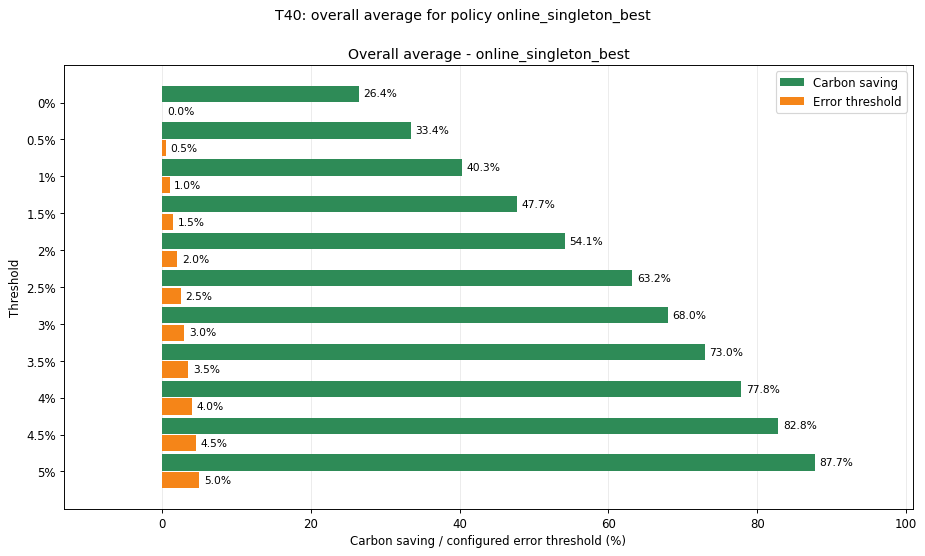

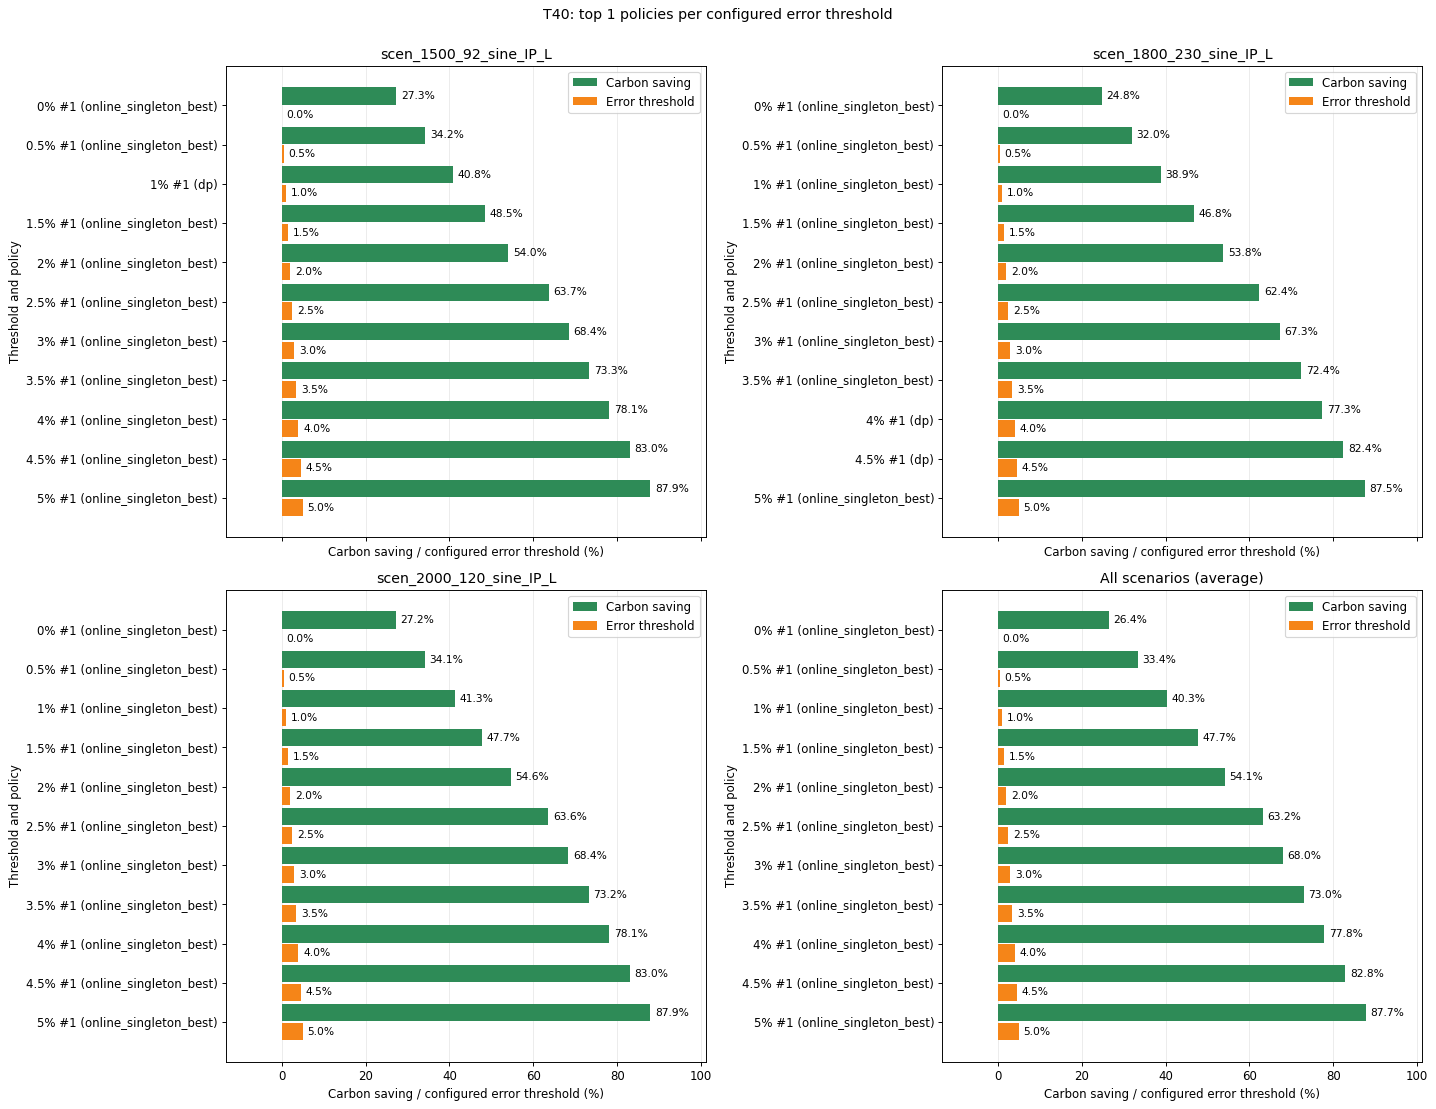

In [23]:
def _select_top_policies(summary, group_columns, top_n):
    """Rank policies by carbon saving within each threshold/scenario group."""
    sort_columns = [*group_columns, "mean_carb_saving", "policy"]
    sort_order = [True] * len(group_columns) + [False, True]
    ranked = (
        summary.sort_values(sort_columns, ascending=sort_order, kind="stable")
        .groupby(group_columns, sort=False)
        .head(top_n)
        .copy()
    )
    ranked["rank"] = ranked.groupby(group_columns, sort=False).cumcount() + 1
    return ranked


def analyze_error_threshold_runs(data, *, run_id="T40", top_n=1, exclude_offline=True):
    """Build and return threshold tables and summaries for later display or plotting."""
    if not isinstance(data, pd.DataFrame):
        raise TypeError("data must be a pandas DataFrame")
    if not isinstance(top_n, int) or isinstance(top_n, bool) or top_n < 1:
        raise ValueError("top_n must be a positive integer")

    # Check the input schema first, so missing metrics fail with a useful message.
    required_columns = {
        "run_id",
        "thresh",
        "scenario_id",
        "policy",
        "path",
        "carb_saving",
        "error",
        "elapsed_s",
        "solver_ms",
    }
    missing_columns = required_columns - set(data.columns)
    if missing_columns:
        raise ValueError(f"Dataframe is missing required columns: {sorted(missing_columns)}")

    # Tiny tweak: keep only runs such that path starts with run_id
    data = data.loc[data["path"].str.startswith(run_id, na=False)]

    # Restrict the input to the requested battery run and ensure its thresholds
    # really came through from the per-scenario configuration files.
    selected_runs = data.loc[data["run_id"].eq(run_id)].copy()
    if selected_runs.empty:
        raise ValueError(f"No results found for run_id={run_id!r}")
    if selected_runs["thresh"].isna().any():
        missing_paths = selected_runs.loc[
            selected_runs["thresh"].isna(), "path"
        ].unique().tolist()
        raise ValueError(
            f"{run_id} runs are missing max_error_threshold config values: {missing_paths}"
        )

    # Offline policies can be included when comparing a broader set of strategies.
    if exclude_offline:
        selected_runs = selected_runs.loc[
            ~selected_runs["policy"].str.startswith("offline_", na=False)
        ].copy()
    if selected_runs.empty:
        raise ValueError(f"No eligible results found for run_id={run_id!r}")

    # Average duplicate runs inside each scenario first. This gives every
    # scenario equal weight in the all-scenarios comparison, regardless of how
    # many repeated runs it contains. The time columns are means in seconds/ms.
    scenario_summary = (
        selected_runs.groupby(["thresh", "policy", "scenario_id"], as_index=False)
        .agg(
            mean_carb_saving=("carb_saving", "mean"),
            mean_error=("error", "mean"),
            elapsed_s=("elapsed_s", "mean"),
            solver_ms=("solver_ms", "mean"),
            run_count=("path", "nunique"),
        )
    )
    overall_summary = (
        scenario_summary.groupby(["thresh", "policy"], as_index=False)
        .agg(
            mean_carb_saving=("mean_carb_saving", "mean"),
            mean_error=("mean_error", "mean"),
            elapsed_s=("elapsed_s", "mean"),
            solver_ms=("solver_ms", "mean"),
            scenario_count=("scenario_id", "nunique"),
            run_count=("run_count", "sum"),
        )
    )

    # Rank policies independently in every scenario and in the overall average.
    top_by_scenario = _select_top_policies(
        scenario_summary, ["scenario_id", "thresh"], top_n
    )
    top_overall = _select_top_policies(overall_summary, ["thresh"], top_n)

    return {
        "run_id": run_id,
        "table_top_n": top_n,
        "filtered_runs": selected_runs,
        "scenario_summary": scenario_summary,
        "overall_summary": overall_summary,
        "top_by_scenario": top_by_scenario,
        "top_overall": top_overall,
    }


def _get_threshold_analysis_summaries(analysis):
    """Validate analysis output and return its summaries and run label."""
    if not isinstance(analysis, dict):
        raise TypeError("analysis must be the result returned by analyze_error_threshold_runs")
    try:
        scenario_summary = analysis["scenario_summary"]
        overall_summary = analysis["overall_summary"]
        run_id = analysis["run_id"]
    except KeyError as exc:
        raise ValueError("analysis is missing summaries from analyze_error_threshold_runs") from exc
    if not isinstance(scenario_summary, pd.DataFrame) or not isinstance(overall_summary, pd.DataFrame):
        raise TypeError("analysis summaries must be pandas DataFrames")
    return scenario_summary, overall_summary, run_id


def display_error_threshold_tables(analysis):
    """Display the scenario-specific and overall tables returned by the analyzer."""
    _get_threshold_analysis_summaries(analysis)
    try:
        table_top_n = analysis["table_top_n"]
        top_by_scenario = analysis["top_by_scenario"]
        top_overall = analysis["top_overall"]
    except KeyError as exc:
        raise ValueError("analysis is missing ranked tables from analyze_error_threshold_runs") from exc

    # Display tables separately so callers can put them after their plots.
    display_by_scenario(
        top_by_scenario,
        title=f"Top {table_top_n} policies per error threshold and scenario",
    )
    _display(
        HTML(
            f"<h2>Top {table_top_n} policies per error threshold, averaged across scenarios</h2>"
        )
    )
    _display(top_overall)
    return top_by_scenario, top_overall


def _render_threshold_comparison(plot_specs, *, header, show_rank=True, show_policy=True):
    """Render shared paired-bar styling for ranked and policy-specific plots."""
    if not plot_specs:
        raise ValueError("At least one threshold comparison is required")
    x_values = [0.0]
    for _, plot_data in plot_specs:
        x_values.extend(plot_data["mean_carb_saving"].tolist())
        x_values.extend(plot_data["thresh"].tolist())
    x_min, x_max = min(x_values), max(x_values)
    x_padding = max(2.0, (x_max - x_min) * 0.15)

    # Share the horizontal scale to make all panels directly comparable.
    ncols = 2 if len(plot_specs) > 1 else 1
    nrows = (len(plot_specs) + ncols - 1) // ncols
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(17 if ncols == 2 else 11, 6.5 * nrows),
        sharex=True,
    )
    axes = list(fig.axes)
    bar_height = 0.44
    bar_offset = 0.24
    for ax, (plot_title, plot_data) in zip(axes, plot_specs):
        # Keep policies for a threshold together, ordered by threshold and rank.
        plot_data = plot_data.sort_values(
            ["thresh", "rank"], kind="stable"
        ).reset_index(drop=True)
        positions = list(range(len(plot_data)))
        thresholds = plot_data["thresh"].tolist()
        carbon_savings = plot_data["mean_carb_saving"].tolist()
        saving_bars = ax.barh(
            [position - bar_offset for position in positions],
            carbon_savings,
            height=bar_height,
            color="#2e8b57",
            label="Carbon saving",
        )
        threshold_bars = ax.barh(
            [position + bar_offset for position in positions],
            thresholds,
            height=bar_height,
            color="#f58518",
            label="Error threshold",
        )

        # Put exact percentage labels just beyond the end of each bar.
        for bars in (saving_bars, threshold_bars):
            for bar in bars:
                value = bar.get_width()
                is_positive = value >= 0
                ax.annotate(
                    f"{value:.1f}%",
                    xy=(value, bar.get_y() + bar.get_height() / 2),
                    xytext=(4 if is_positive else -4, 0),
                    textcoords="offset points",
                    ha="left" if is_positive else "right",
                    va="center",
                    fontsize=9,
                )

        ax.set_yticks(positions)
        if show_rank:
            labels = [
                f"{threshold:g}% #{rank} ({policy})"
                for threshold, rank, policy in zip(
                    thresholds, plot_data["rank"], plot_data["policy"]
                )
            ]
        elif show_policy:
            labels = [
                f"{threshold:g}% ({policy})"
                for threshold, policy in zip(thresholds, plot_data["policy"])
            ]
        else:
            labels = [f"{threshold:g}%" for threshold in thresholds]
        ax.set_yticklabels(labels)
        ax.set_xlim(x_min - x_padding, x_max + x_padding)
        ax.set_xlabel("Carbon saving / configured error threshold (%)")
        ax.set_ylabel("Threshold and policy" if show_policy else "Threshold")
        ax.set_title(plot_title)
        ax.grid(axis="x", alpha=0.25)
        ax.set_axisbelow(True)
        ax.legend()
        ax.invert_yaxis()

    # Hide an unused panel when there is an odd number of comparison plots.
    for ax in axes[len(plot_specs):]:
        ax.set_visible(False)
    fig.suptitle(header, y=1.0)
    fig.tight_layout()
    _display(fig)
    plt.close(fig)
    return fig


def plot_error_threshold_comparison(analysis, *, top_n=1):
    """Plot the top-N policies per threshold for each scenario and overall."""
    if not isinstance(top_n, int) or isinstance(top_n, bool) or top_n < 1:
        raise ValueError("top_n must be a positive integer")
    scenario_summary, overall_summary, run_id = _get_threshold_analysis_summaries(analysis)

    # Rank policies from complete summaries, independent of the table top-N.
    top_by_scenario = _select_top_policies(
        scenario_summary, ["scenario_id", "thresh"], top_n
    )
    top_overall = _select_top_policies(overall_summary, ["thresh"], top_n)

    # Make one panel per scenario, plus a panel averaging the scenarios equally.
    plot_specs = [
        (
            str(scenario_id),
            top_by_scenario.loc[top_by_scenario["scenario_id"].eq(scenario_id)],
        )
        for scenario_id in sorted(top_by_scenario["scenario_id"].unique())
    ]
    plot_specs.append(("All scenarios (average)", top_overall))
    return _render_threshold_comparison(
        plot_specs,
        header=f"{run_id}: top {top_n} policies per configured error threshold",
    )


def plot_overall_policy_comparison(analysis, policy):
    """Plot one explicitly selected policy using its across-scenario averages."""
    if not isinstance(policy, str) or not policy:
        raise ValueError("policy must be a non-empty policy name")
    _, overall_summary, run_id = _get_threshold_analysis_summaries(analysis)

    # Filter to the requested policy instead of ranking policies by top-N.
    policy_results = overall_summary.loc[overall_summary["policy"].eq(policy)].copy()
    if policy_results.empty:
        available = sorted(overall_summary["policy"].dropna().astype(str).unique())
        raise ValueError(
            f"Policy {policy!r} has no overall results; available policies: {available}"
        )
    policy_results = policy_results.sort_values("thresh", kind="stable").reset_index(drop=True)
    policy_results["rank"] = 1

    # The policy is repeated in the panel title and figure header for clarity.
    return _render_threshold_comparison(
        [(f"Overall average - {policy}", policy_results)],
        header=f"{run_id}: overall average for policy {policy}",
        show_rank=False,
        show_policy=False,
    )


# Analyze first without displaying output so the plots can appear before the tables.
t40_analysis = analyze_error_threshold_runs(df_all, run_id="T40", top_n=2)
t40_policy_figure = plot_overall_policy_comparison(
    t40_analysis, policy="online_singleton_best"
)
t40_figure = plot_error_threshold_comparison(t40_analysis)  # Plot defaults to top_n=1.
# To plot two top policies per threshold, pass top_n=2 to the function above.


In [24]:
def plot_policy_saving_by_threshold(analysis, *, scenario_id=None):
    """Plot each policy's saving curve for one scenario or the overall average."""
    scenario_summary, overall_summary, run_id = _get_threshold_analysis_summaries(analysis)

    # Use scenario-level results for one scenario, or the equal-weight average
    # across scenarios when scenario_id is omitted.
    if scenario_id is None:
        plot_data = overall_summary.copy()
        view_label = "All scenarios (average)"
    else:
        plot_data = scenario_summary.loc[
            scenario_summary["scenario_id"].eq(scenario_id)
        ].copy()
        if plot_data.empty:
            available = sorted(scenario_summary["scenario_id"].dropna().unique())
            raise ValueError(
                f"No results for scenario_id={scenario_id!r}; available scenarios: {available}"
            )
        view_label = f"Scenario {scenario_id}"

    required_columns = {"thresh", "policy", "mean_carb_saving"}
    missing_columns = required_columns - set(plot_data.columns)
    if missing_columns:
        raise ValueError(f"Analysis summary is missing columns: {sorted(missing_columns)}")
    if plot_data["policy"].isna().any():
        raise ValueError("Analysis summary contains rows without a policy name")

    # Strip online/offline prefixes so matching variants share the same color.
    def policy_color_group(policy):
        if policy.startswith("offline_"):
            return policy.removeprefix("offline_")
        if policy.startswith("online_"):
            return policy.removeprefix("online_")
        return policy

    # Draw online traces first so offline markers remain visible when values nearly overlap.
    policy_names = sorted(
        plot_data["policy"].unique(),
        key=lambda policy: (policy.startswith("offline_"), policy),
    )
    color_groups = sorted({policy_color_group(policy) for policy in policy_names})
    palette = sns.husl_palette(n_colors=max(len(color_groups), 1)).as_hex()
    colors = dict(zip(color_groups, palette))

    # Plotly's legend is interactive: click an entry to hide/show it, or double-click to isolate it.
    import plotly.graph_objects as go

    fig = go.Figure()
    policy_styles = {}
    for policy in policy_names:
        policy_rows = plot_data.loc[plot_data["policy"].eq(policy)].sort_values(
            "thresh", kind="stable"
        )
        is_offline = policy.startswith("offline_")
        color = colors[policy_color_group(policy)]
        style = {
            "color": color,
            "symbol": "diamond" if is_offline else "circle",
            "size": 11 if is_offline else 9,
            "opacity": 0.7 if is_offline else 1.0,
        }
        policy_styles[policy] = style
        fig.add_trace(
            go.Scatter(
                x=policy_rows["thresh"],
                y=policy_rows["mean_carb_saving"],
                mode="lines",
                name=policy,
                legendgroup=policy,
                line={
                    "color": color,
                    "dash": "dash" if is_offline else "solid",
                    "width": 3,
                },
                opacity=style["opacity"],
                hoverinfo="skip",
            )
        )

    # Unified hover follows trace order; sort point traces by saving independently at each threshold.
    hover_rows = plot_data.sort_values(
        ["thresh", "mean_carb_saving", "policy"],
        ascending=[True, False, True],
        kind="stable",
    )
    for point in hover_rows.itertuples(index=False):
        style = policy_styles[point.policy]
        fig.add_trace(
            go.Scatter(
                x=[point.thresh],
                y=[point.mean_carb_saving],
                mode="markers",
                name=point.policy,
                legendgroup=point.policy,
                showlegend=False,
                marker={
                    "color": style["color"],
                    "symbol": style["symbol"],
                    "size": style["size"],
                    "line": {"color": "white", "width": 1},
                },
                opacity=style["opacity"],
                hovertemplate=(
                    "<b>%{fullData.name}</b><br>"
                    "Error threshold: %{x:.2f}%<br>"
                    "Carbon saving: %{y:.2f}%<extra></extra>"
                ),
            )
        )

    fig.update_layout(
        width=1500,
        height=900,
        template="plotly_white",
        title={
            "text": (
                f"{run_id}: policy carbon saving vs error threshold"
                f"<br><sup>{view_label} - click legend entries to show/hide policies</sup>"
            ),
            "x": 0.5,
            "xanchor": "center",
            "font": {"size": 20},
        },
        legend={
            "title": {"text": "Policy"},
            "font": {"size": 13},
            "itemclick": "toggle",
            "itemdoubleclick": "toggleothers",
            "groupclick": "togglegroup",
            "x": 1.02,
            "y": 1,
            "xanchor": "left",
            "yanchor": "top",
        },
        hovermode="x unified",
        margin={"l": 100, "r": 310, "t": 125, "b": 90},
    )
    fig.update_xaxes(
        title_text="Error threshold (%)",
        ticksuffix="%",
        tickfont={"size": 13},
        title_font={"size": 16},
        showgrid=True,
    )
    fig.update_yaxes(
        title_text="Carbon saving (%)",
        ticksuffix="%",
        tickfont={"size": 13},
        title_font={"size": 16},
        showgrid=True,
    )
    _display(fig)
    return fig


# Include offline results for this plot so they can be compared with online policies.
t40_all_policies_analysis = analyze_error_threshold_runs(
    df_all, run_id="T40", top_n=1, exclude_offline=False
)
t40_all_policies_curve = plot_policy_saving_by_threshold(t40_all_policies_analysis)
# For one scenario, pass its ID, e.g. scenario_id="scen_1500_92_sine_IP_L".
